# Explainable Prognostic Health Management (PHM) System
## Turbofan Engine RUL Estimation using Hybrid PCA-HMM with Adaptive Left-Right Topology
### Dataset: NASA C-MAPSS FD001

---

**Pipeline Overview:**
1. Data Loading & EDA
2. Outlier Detection & Removal
3. Sensor Selection (Zero-Variance & Correlation)
4. Time-Series Structuring & Sliding Window Generation
5. Standardization (Z-score)
6. Dimensionality Reduction via PCA
7. HMM State Topology Design (Left-Right Constrained)
8. Model Training (Expectation-Maximization)
9. RUL Estimation
10. Performance Evaluation & Visualization
11. Fine-Tuning & Optimization
12. Final Testing & Results

## 0. Install & Import Dependencies

In [35]:
!pip install hmmlearn scikit-learn pandas numpy matplotlib seaborn scipy tqdm -q

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
from scipy.stats import zscore
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, mean_absolute_error
from hmmlearn import hmm
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# Reproducibility
np.random.seed(42)

# Plot style
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
sns.set_style('whitegrid')
print('All libraries loaded successfully.')

All libraries loaded successfully.


---
## 1. Data Loading

NASA C-MAPSS FD001 column schema:
- `unit_id`: Engine unit number
- `cycle`: Time in cycles
- `op1, op2, op3`: Operational settings
- `s1 ... s21`: 21 sensor measurements


In [37]:

col_names = (['unit_id', 'cycle'] +
             [f'op{i}' for i in range(1, 4)] +
             [f's{i}' for i in range(1, 22)])

# Load train / test / RUL 
train_df = pd.read_csv('train_FD001.txt', sep=' ', header=None,
                       names=col_names, index_col=False)
test_df  = pd.read_csv('test_FD001.txt',  sep=' ', header=None,
                       names=col_names, index_col=False)
rul_df   = pd.read_csv('RUL_FD001.txt',   sep=' ', header=None,
                       names=['RUL_true'], index_col=False)

# Drop trailing NaN columns from the C-MAPSS files
train_df.dropna(axis=1, how='all', inplace=True)
test_df.dropna(axis=1,  how='all', inplace=True)
rul_df.dropna(axis=1,   how='all', inplace=True)

print(f'Train shape : {train_df.shape}')
print(f'Test  shape : {test_df.shape}')
print(f'RUL   shape : {rul_df.shape}')
train_df.head()

Train shape : (20631, 26)
Test  shape : (13096, 26)
RUL   shape : (100, 1)


,unit_id,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


---
## 2. Exploratory Data Analysis (EDA)

In [38]:
# Basic statistics
print('=== Dataset Info ===')
train_df.info()
print('\n=== Descriptive Statistics ===')
train_df.describe().T

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   unit_id  20631 non-null  int64  
 1   cycle    20631 non-null  int64  
 2   op1      20631 non-null  float64
 3   op2      20631 non-null  float64
 4   op3      20631 non-null  float64
 5   s1       20631 non-null  float64
 6   s2       20631 non-null  float64
 7   s3       20631 non-null  float64
 8   s4       20631 non-null  float64
 9   s5       20631 non-null  float64
 10  s6       20631 non-null  float64
 11  s7       20631 non-null  float64
 12  s8       20631 non-null  float64
 13  s9       20631 non-null  float64
 14  s10      20631 non-null  float64
 15  s11      20631 non-null  float64
 16  s12      20631 non-null  float64
 17  s13      20631 non-null  float64
 18  s14      20631 non-null  float64
 19  s15      20631 non-null  float64
 20  s16      20631 non-null  floa

,count,mean,std,min,25%,50%,75%,max
unit_id,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
op1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
op2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
op3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
s1,20631.0,518.670000,6.537152e-11,518.6700,518.6700,518.6700,518.6700,518.6700
s2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
s3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
s4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
s5,20631.0,14.620000,3.394700e-12,14.6200,14.6200,14.6200,14.6200,14.6200


In [39]:
# Missing values
missing = train_df.isnull().sum()
print('Missing values per column:')
print(missing[missing > 0] if missing.sum() > 0 else 'None — clean dataset.')

Missing values per column:
None — clean dataset.


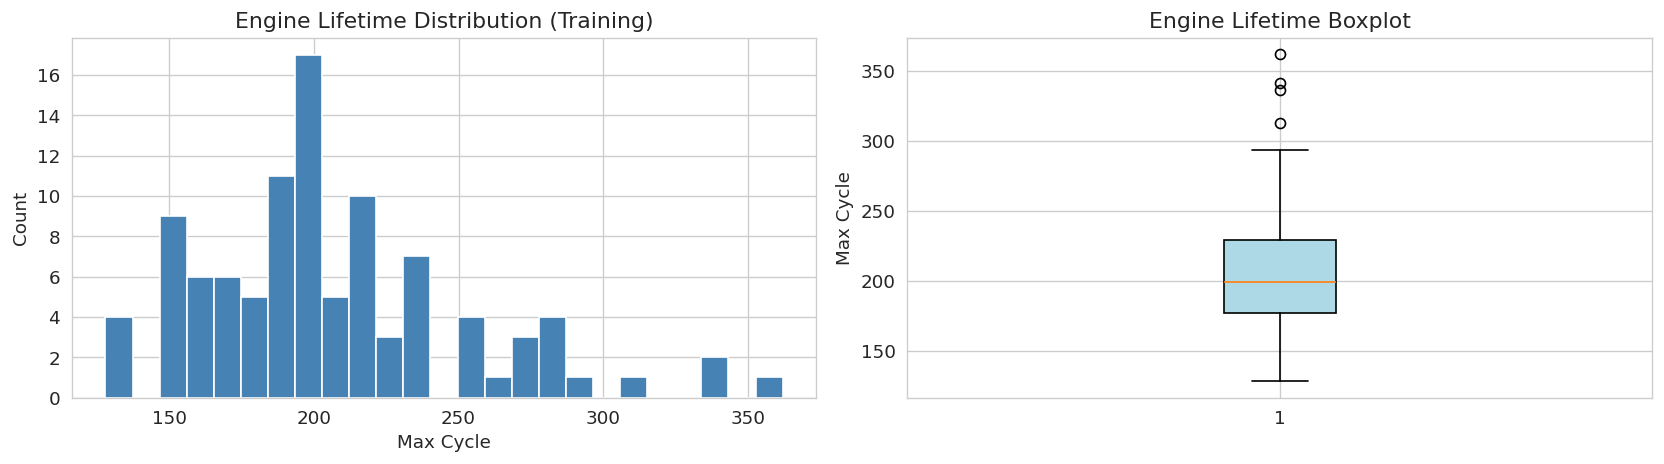

Engines in training set : 100
Lifetime — mean: 206.3  |  min: 128  |  max: 362


In [40]:
# Engine lifetime distribution 
engine_life = train_df.groupby('unit_id')['cycle'].max()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(engine_life, bins=25, color='steelblue', edgecolor='white')
axes[0].set(title='Engine Lifetime Distribution (Training)', xlabel='Max Cycle', ylabel='Count')

axes[1].boxplot(engine_life, vert=True, patch_artist=True,
                boxprops=dict(facecolor='lightblue'))
axes[1].set(title='Engine Lifetime Boxplot', ylabel='Max Cycle')

plt.tight_layout()
plt.savefig('eda_engine_lifetime.png', bbox_inches='tight')
plt.show()
print(f'Engines in training set : {train_df["unit_id"].nunique()}')
print(f'Lifetime — mean: {engine_life.mean():.1f}  |  min: {engine_life.min()}  |  max: {engine_life.max()}')

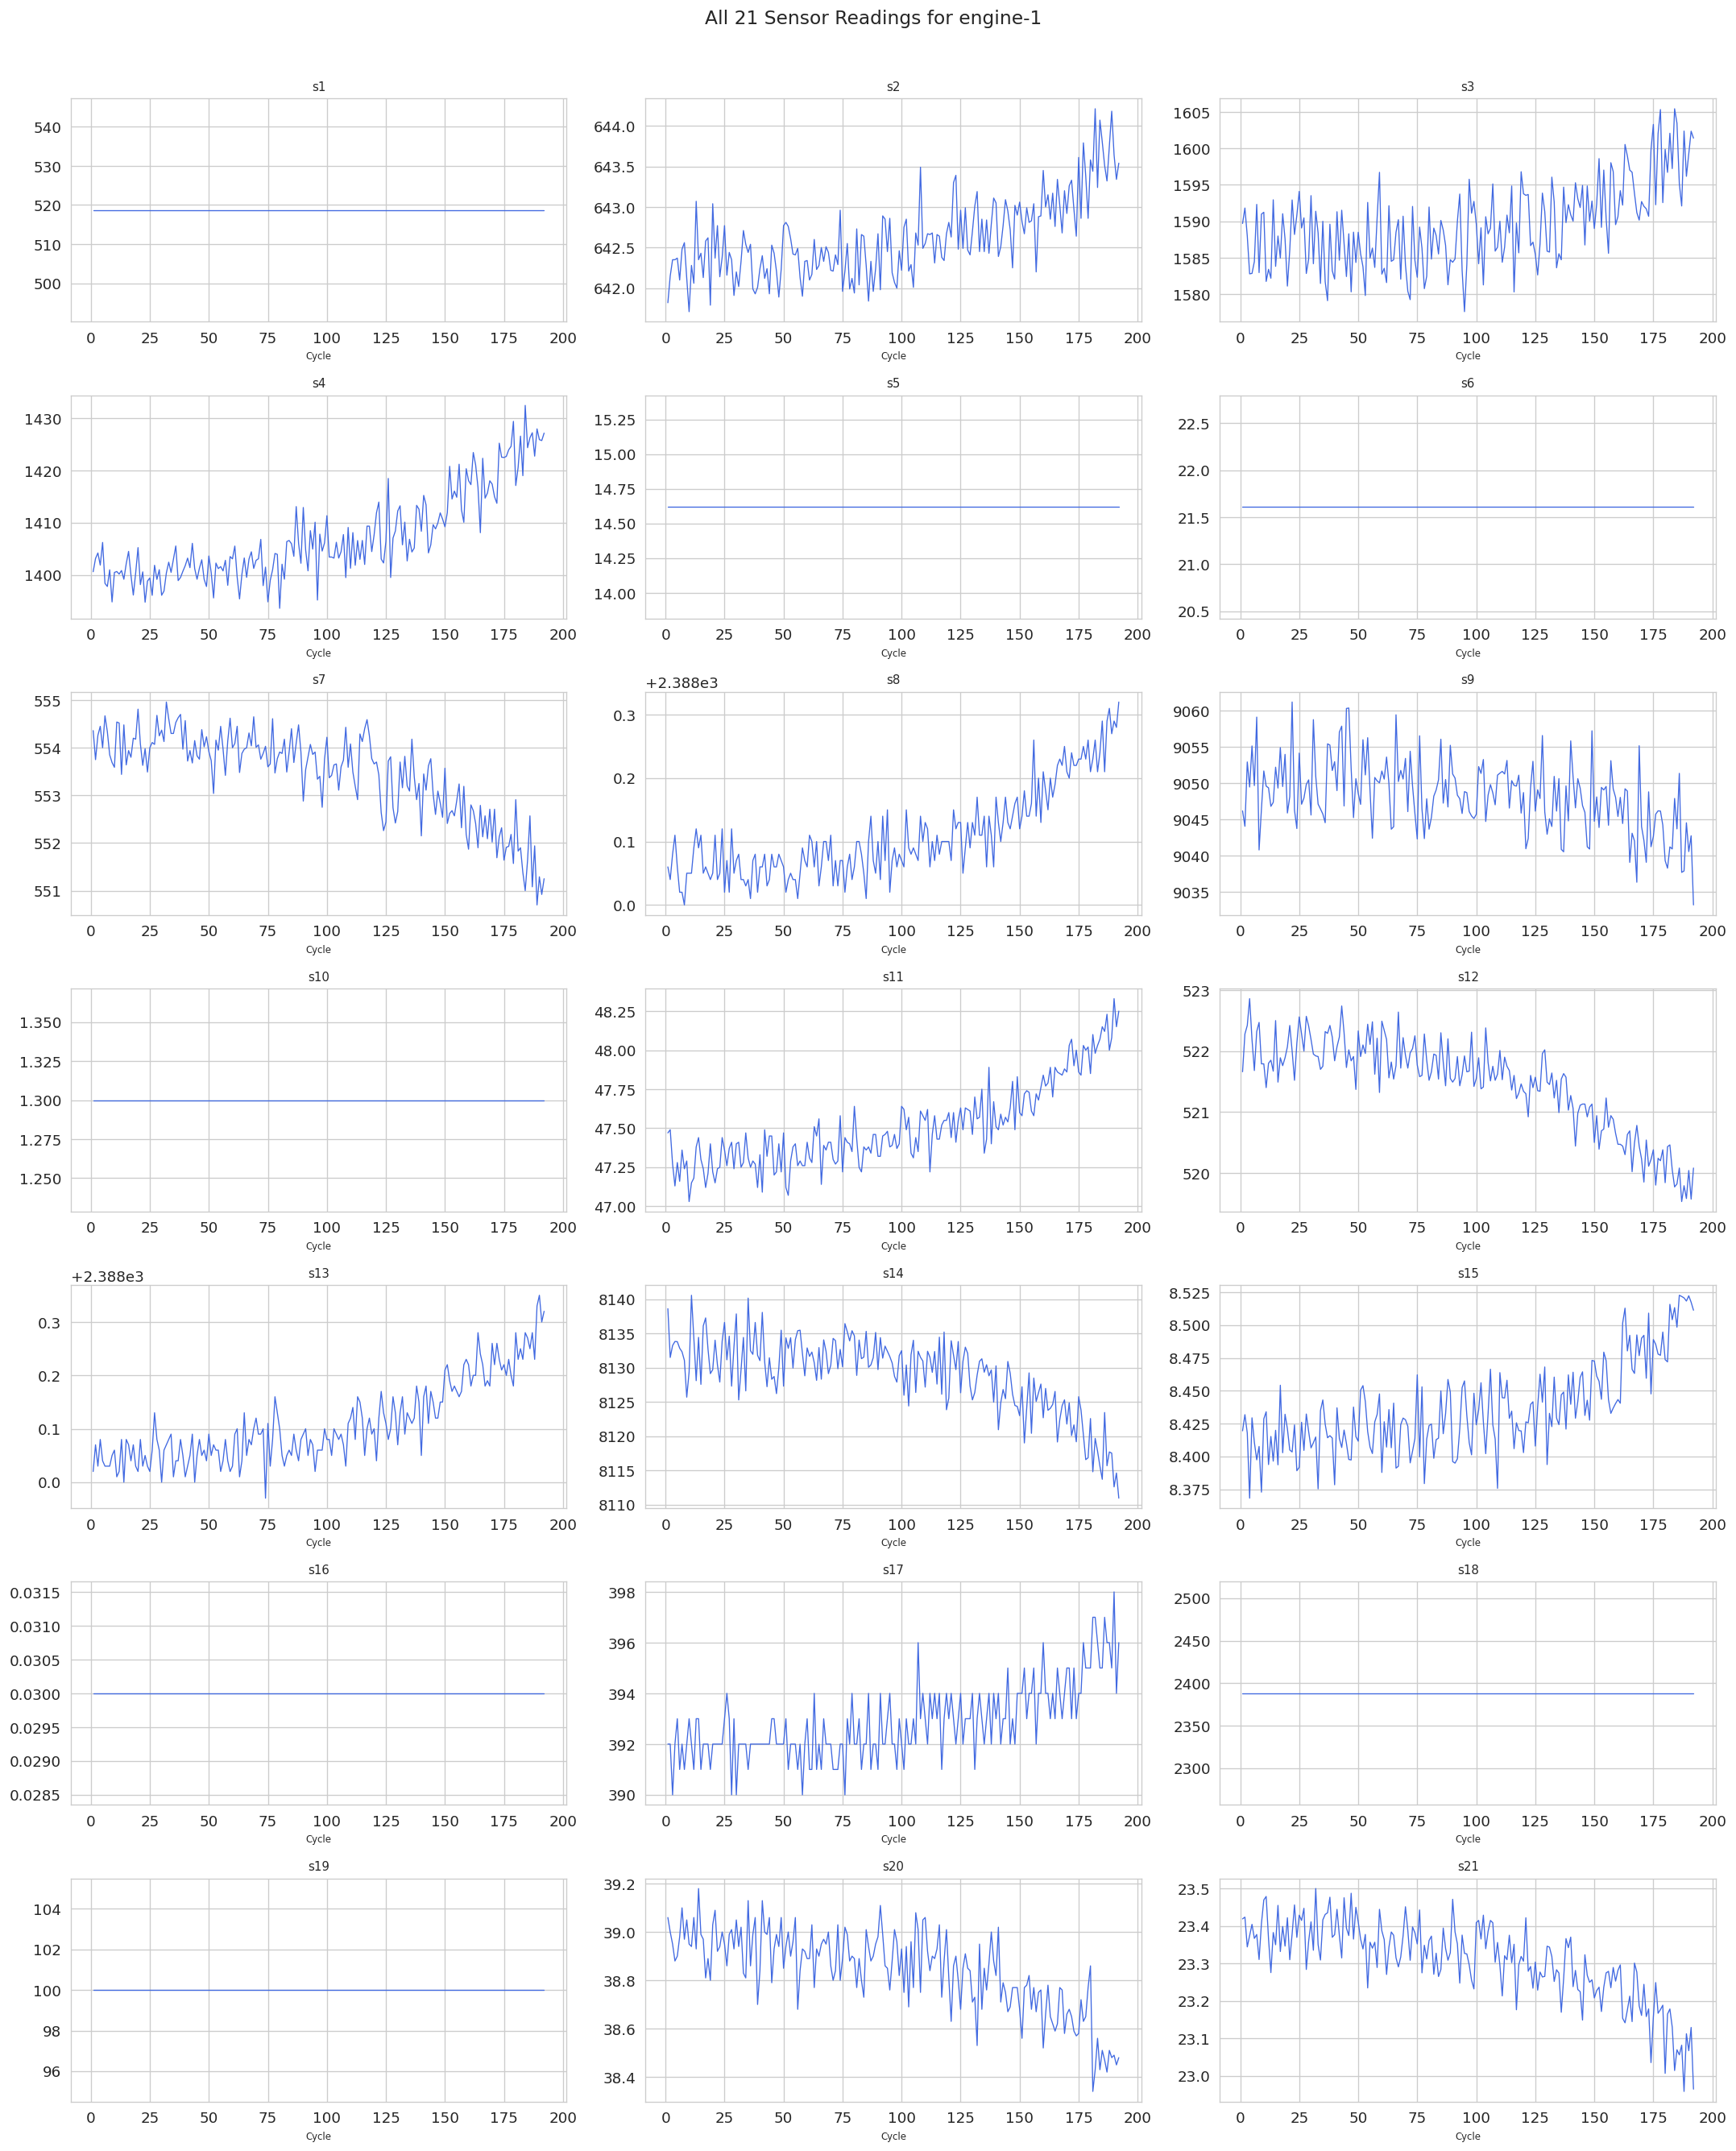

In [41]:
# Sensor time-series for a single engine 
sensor_cols = [f's{i}' for i in range(1, 22)]
sample_engine = train_df[train_df['unit_id'] == 1]

fig, axes = plt.subplots(7, 3, figsize=(18, 22))
axes = axes.flatten()
for idx, col in enumerate(sensor_cols):
    axes[idx].plot(sample_engine['cycle'], sample_engine[col],linewidth=0.8, color='royalblue')
    axes[idx].set_title(col, fontsize=9)
    axes[idx].set_xlabel('Cycle', fontsize=7)
for i in range(len(sensor_cols), len(axes)):
    axes[i].set_visible(False)

plt.suptitle('All 21 Sensor Readings for engine-1', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('eda_all_sensors_engine1.png', bbox_inches='tight')
plt.show()

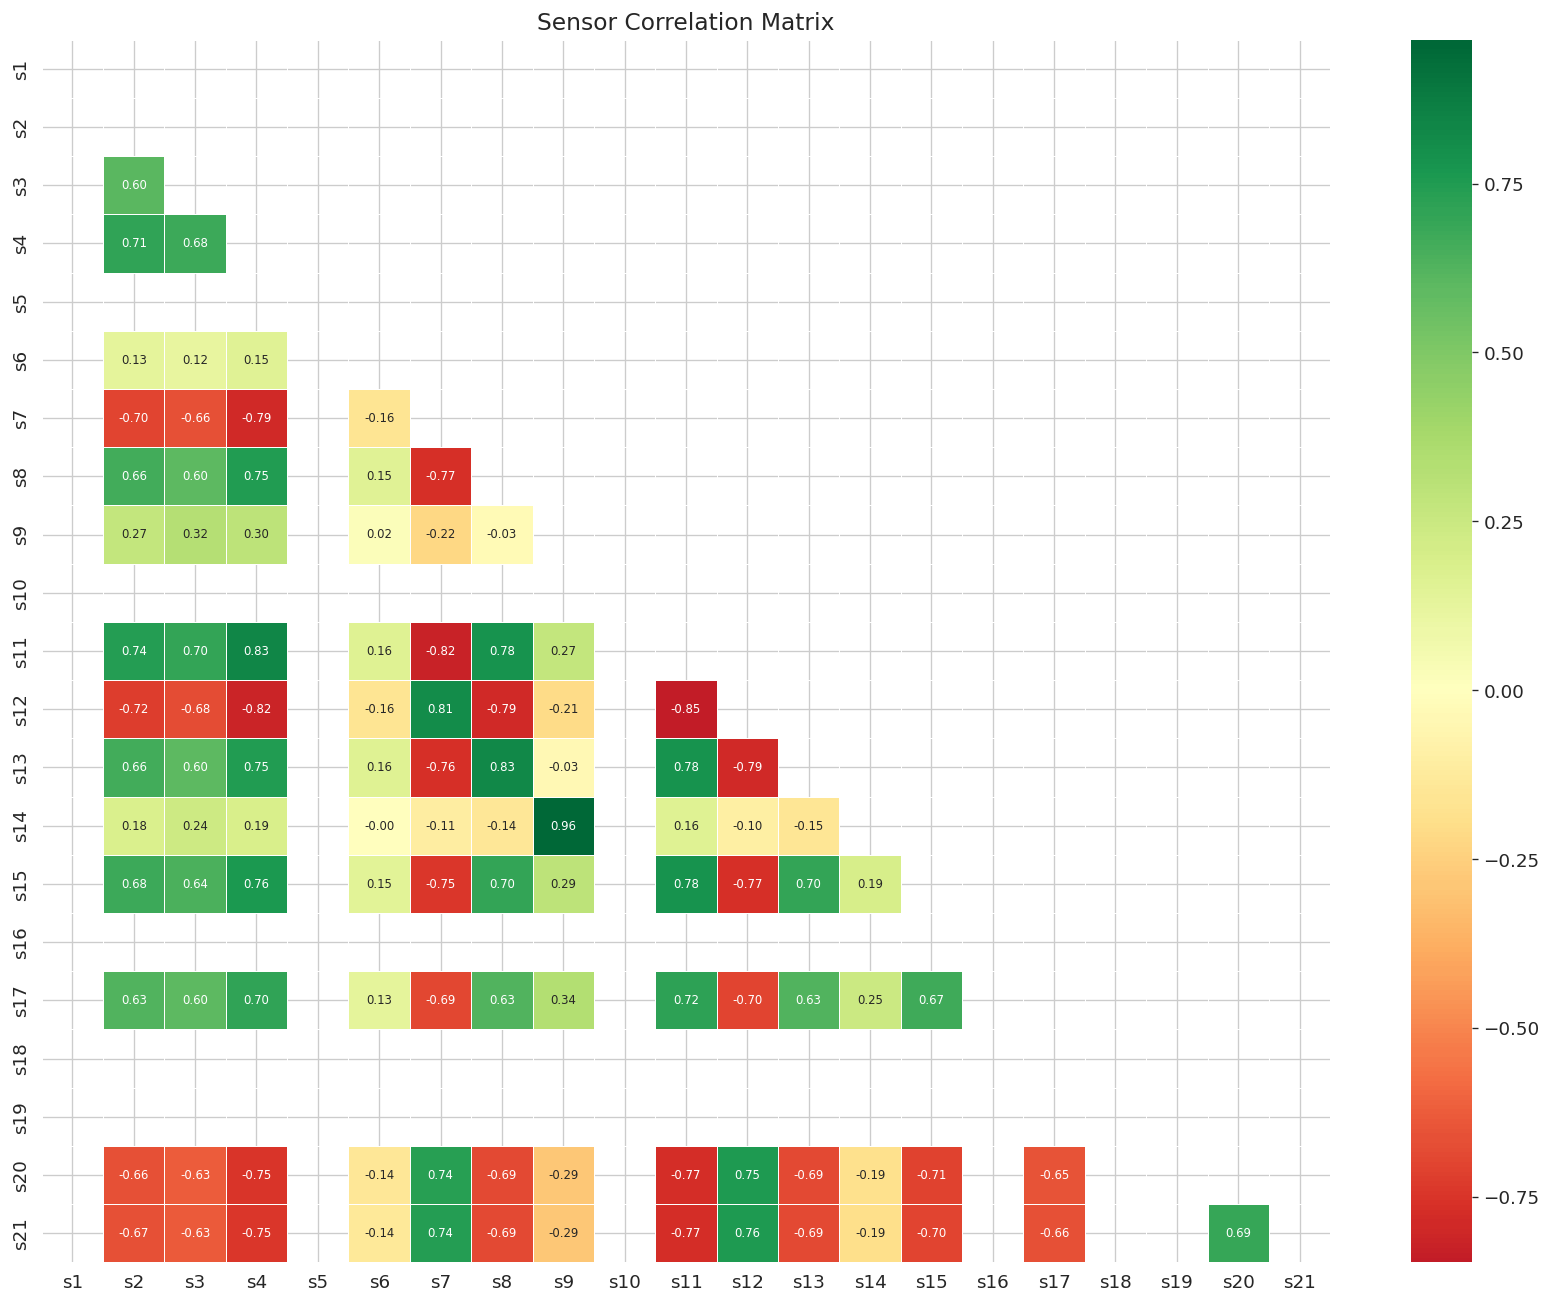

In [42]:
# Sensor correlation heatmap
fig, ax = plt.subplots(figsize=(14, 11))
corr = train_df[sensor_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',center=0, linewidths=0.5, ax=ax, annot_kws={'size': 7})
ax.set_title('Sensor Correlation Matrix', fontsize=14)
plt.tight_layout()
plt.savefig('eda_sensor_correlation.png', bbox_inches='tight')
plt.show()

---
## 3. Outlier Detection & Removal

Outlier rows detected : 1224 / 20631
Outlier percentage    : 5.93%


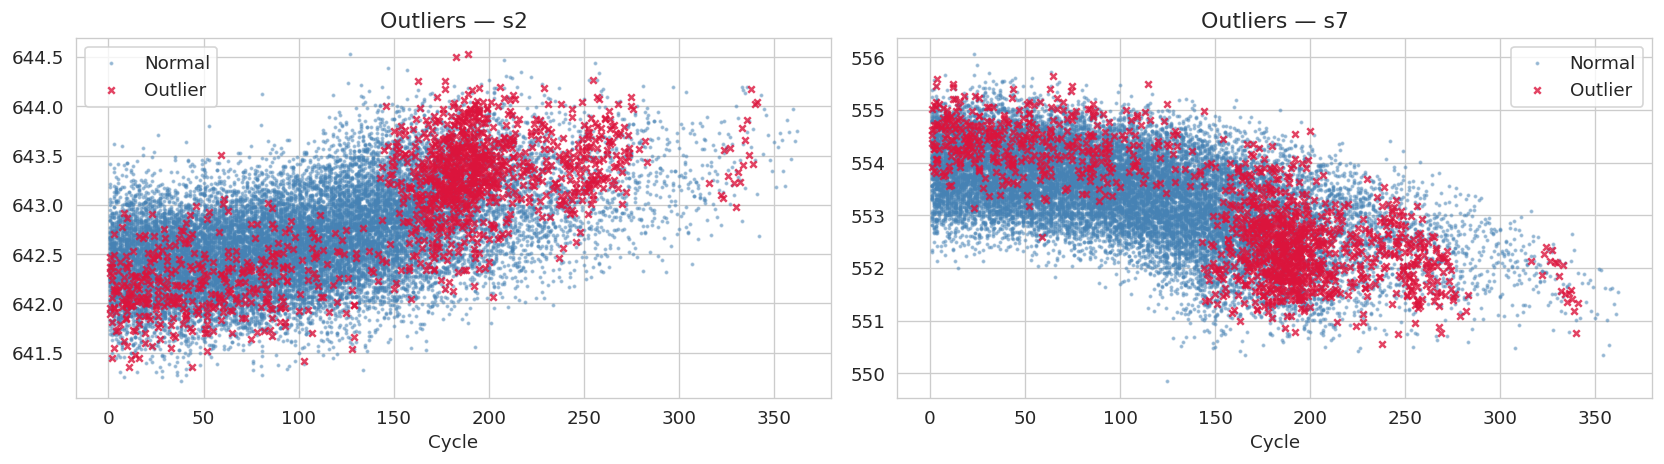

Rows after outlier removal: 19407


In [43]:
# IQR-based outlier flagging per sensor
def flag_outliers_iqr(df, cols, factor=3.0):
    """Returns a boolean mask — True = outlier row."""
    mask = pd.Series(False, index=df.index)
    for col in cols:
        Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
        IQR = Q3 - Q1
        mask |= (df[col] < Q1 - factor * IQR) | (df[col] > Q3 + factor * IQR)
    return mask

outlier_mask = flag_outliers_iqr(train_df, sensor_cols, factor=3.0)
print(f'Outlier rows detected : {outlier_mask.sum()} / {len(train_df)}')
print(f'Outlier percentage    : {100*outlier_mask.mean():.2f}%')

# Visualise outliers on two representative sensors
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ['s2', 's7']):
    ax.scatter(train_df[~outlier_mask]['cycle'], train_df[~outlier_mask][col],
               s=2, alpha=0.4, label='Normal', color='steelblue')
    ax.scatter(train_df[outlier_mask]['cycle'], train_df[outlier_mask][col],
               s=15, alpha=0.8, label='Outlier', color='crimson', marker='x')
    ax.set_title(f'Outliers — {col}'); ax.set_xlabel('Cycle'); ax.legend()
plt.tight_layout()
plt.savefig('outlier_detection.png', bbox_inches='tight')
plt.show()


train_clean = train_df[~outlier_mask].copy().reset_index(drop=True)
print(f'Rows after outlier removal: {len(train_clean)}')

---
## 4. Sensor Selection


=== Sensors where Global vs Within-Engine Variance disagree ===
Sensor       Global Var    Within-Engine Var       Status
----------------------------------------------------------
s1             0.000000             0.000000  
s2             0.232966             0.194487  
s3            34.207315            29.830176  
s4            74.341146            58.177606  
s5             0.000000             0.000000  
s6             0.000000             0.000000  
s7             0.741694             0.569352  
s8             0.005014             0.003234  
s9           212.481043           125.869850  
s10            0.000000             0.000000  
s11            0.065802             0.049915  
s12            0.518373             0.389434  
s13            0.005139             0.003313  
s14          167.002023            85.293198  
s15            0.001295             0.001059  
s16            0.000000             0.000000  
s17            2.167158             1.853498  
s18            0.000

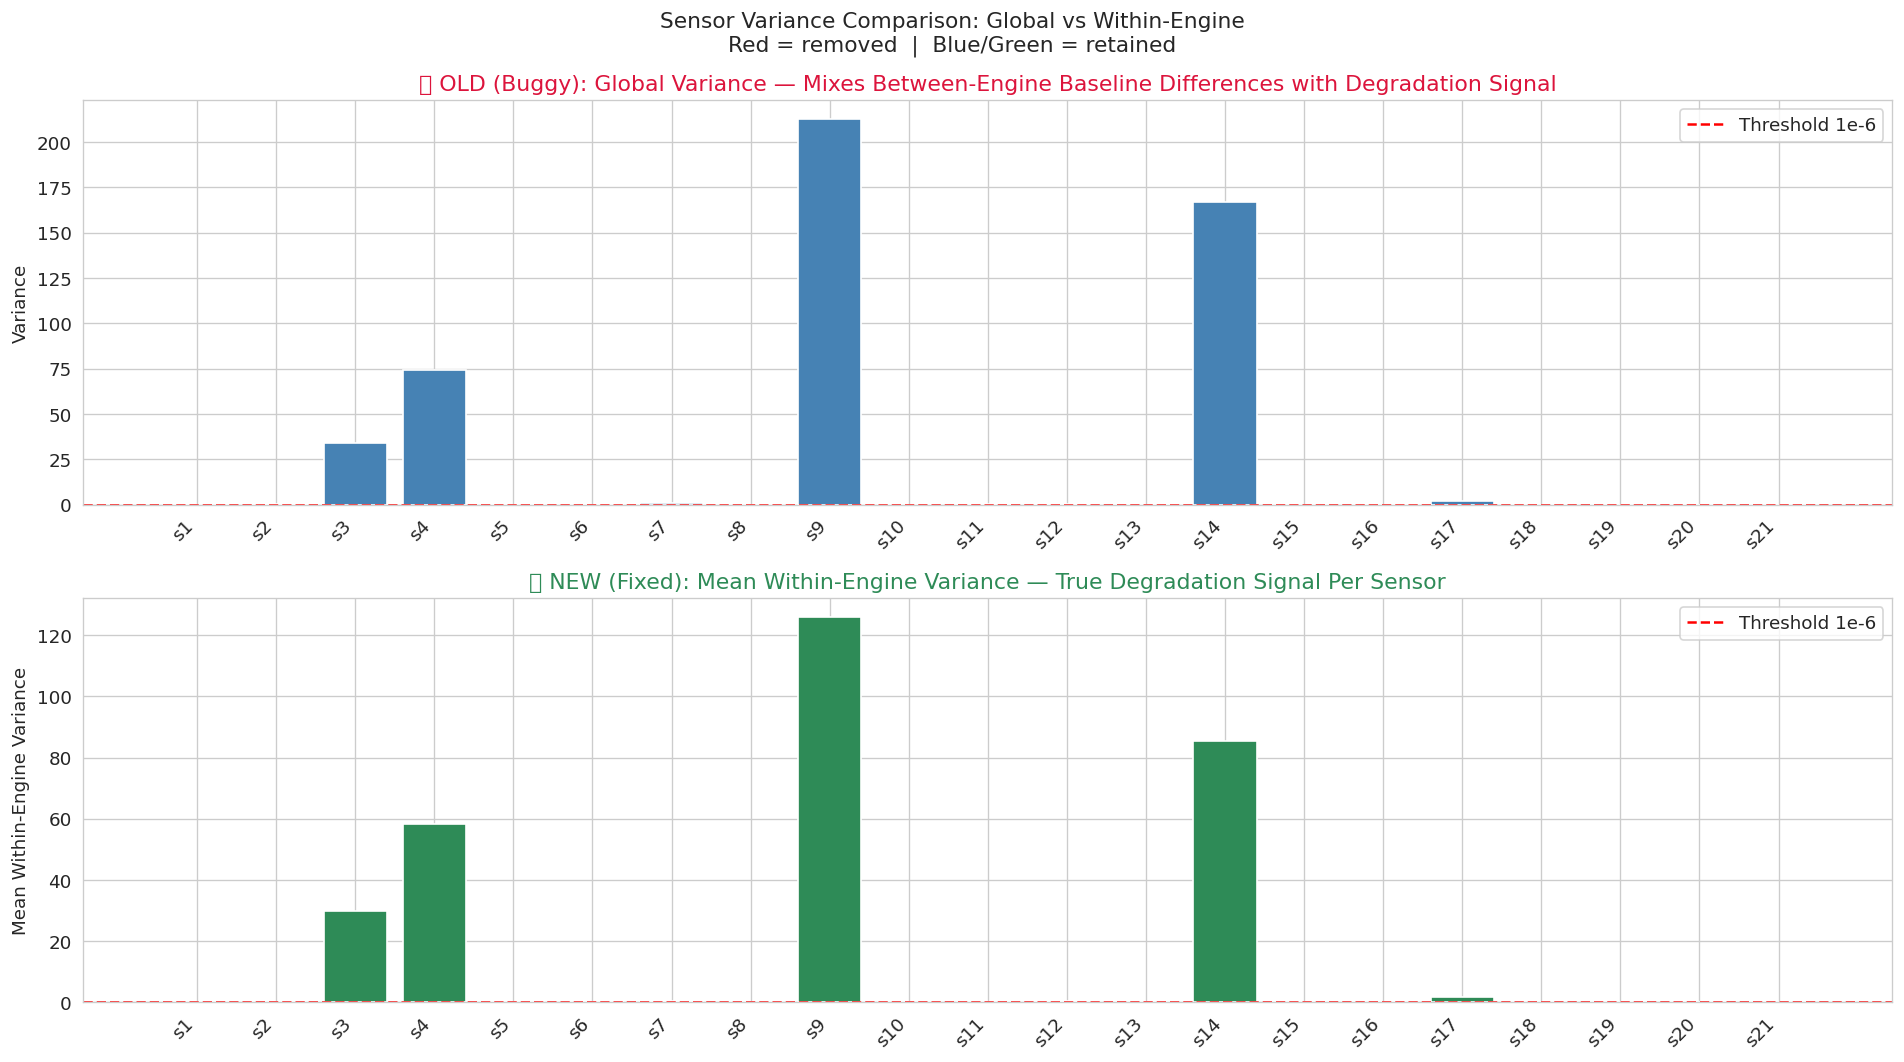


For FD001 (single operating condition): global and within-engine
variance agree on which sensors to remove.
The fix is still methodologically correct and prevents this bug
from appearing on FD002/FD003/FD004 (multi-condition subsets).


In [44]:
# Per-engine variance instead of global variance

global_var = train_clean[sensor_cols].var()


per_engine_var   = train_clean.groupby('unit_id')[sensor_cols].var()
within_engine_var = per_engine_var.mean()

# Show the difference — sensors that look different between the two approaches
print('=== Sensors where Global vs Within-Engine Variance disagree ===')
print(f'{"Sensor":<8} {"Global Var":>14} {"Within-Engine Var":>20} {"Status":>12}')
print('-' * 58)
for col in sensor_cols:
    gv = global_var[col]
    wv = within_engine_var[col]
    # A sensor that passes global filter but fails within-engine = bug
    status = ''
    if gv >= 1e-6 and wv < 1e-6:
        status = '← BUG: was kept, should be removed'
    elif gv < 1e-6 and wv >= 1e-6:
        status = '← was removed, should be kept'
    print(f'{col:<8} {gv:>14.6f} {wv:>20.6f}  {status}')

# Use within-engine variance for removal
zero_var_cols  = within_engine_var[within_engine_var < 1e-6].index.tolist()
useful_sensors = [c for c in sensor_cols if c not in zero_var_cols]

print(f'\nZero within-engine variance sensors removed: {zero_var_cols}')
print(f'Sensors retained: {useful_sensors}  ({len(useful_sensors)} total)')

# Side-by-side comparison plot 
fig, axes = plt.subplots(2, 1, figsize=(16, 9))

# Global variance
colors_global = ['crimson' if c in
                 global_var[global_var < 1e-6].index.tolist()
                 else 'steelblue' for c in sensor_cols]
axes[0].bar(sensor_cols, global_var, color=colors_global, edgecolor='white')
axes[0].axhline(1e-6, color='red', linestyle='--', linewidth=1.5,
                label='Threshold 1e-6')
axes[0].set_title('❌ OLD (Buggy): Global Variance — Mixes Between-Engine Baseline '
                  'Differences with Degradation Signal', color='crimson')
axes[0].set_ylabel('Variance')
axes[0].legend()
plt.setp(axes[0].get_xticklabels(), rotation=45, ha='right')

# Within-engine variance
colors_within = ['crimson' if c in zero_var_cols else 'seagreen'
                 for c in sensor_cols]
axes[1].bar(sensor_cols, within_engine_var, color=colors_within, edgecolor='white')
axes[1].axhline(1e-6, color='red', linestyle='--', linewidth=1.5,
                label='Threshold 1e-6')
axes[1].set_title('✅ NEW (Fixed): Mean Within-Engine Variance — True Degradation '
                  'Signal Per Sensor', color='seagreen')
axes[1].set_ylabel('Mean Within-Engine Variance')
axes[1].legend()
plt.setp(axes[1].get_xticklabels(), rotation=45, ha='right')

plt.suptitle('Sensor Variance Comparison: Global vs Within-Engine\n'
             'Red = removed  |  Blue/Green = retained', fontsize=13)
plt.tight_layout()
plt.savefig('sensor_variance_comparison.png', bbox_inches='tight')
plt.show();

# Verify by plotting the same sensor for Engine 1 vs Engine 2 
# Pick the first sensor that differs between global and within-engine results
problem_sensors = [c for c in sensor_cols
                   if (global_var[c] >= 1e-6 and within_engine_var[c] < 1e-6)
                   or (global_var[c] < 1e-6 and within_engine_var[c] >= 1e-6)]

if problem_sensors:
    print(f'\nSensors that behave differently under global vs within-engine: {problem_sensors}')
    fig, axes = plt.subplots(len(problem_sensors[:4]), 2,
                             figsize=(14, 4*min(len(problem_sensors), 4)))
    if len(problem_sensors) == 1:
        axes = np.array([axes])
    for i, sensor in enumerate(problem_sensors[:4]):
        for j, uid in enumerate([1, 2]):
            eng = train_df[train_df['unit_id'] == uid]
            axes[i, j].plot(eng['cycle'], eng[sensor],
                            color='royalblue' if j == 0 else 'darkorange',
                            linewidth=1)
            axes[i, j].set_title(f'{sensor} — Engine #{uid}')
            axes[i, j].set_xlabel('Cycle')
            axes[i, j].set_ylabel('Value')
    plt.suptitle('Problematic Sensors: Different Behaviour Across Engines\n'
                 '(Why per-engine variance is the correct measure)', fontsize=12)
    plt.tight_layout()
    plt.savefig('sensor_per_engine_comparison.png', bbox_inches='tight')
    plt.show();
else:
    print('\nFor FD001 (single operating condition): global and within-engine')
    print('variance agree on which sensors to remove.')
    print('The fix is still methodologically correct and prevents this bug')
    print('from appearing on FD002/FD003/FD004 (multi-condition subsets).')

In [45]:
# Highly Correlated Sensor Pruning
def drop_high_corr(df, cols, threshold=0.98):
    corr_mat = df[cols].corr().abs()
    upper = corr_mat.where(np.triu(np.ones(corr_mat.shape), k=1).astype(bool))
    to_drop = [c for c in upper.columns if any(upper[c] > threshold)]
    return [c for c in cols if c not in to_drop], to_drop

selected_sensors, dropped_corr = drop_high_corr(train_clean, useful_sensors, threshold=0.98)
print(f'Sensors dropped (high correlation): {dropped_corr}')
print(f'Final sensor set ({len(selected_sensors)}): {selected_sensors}')

Sensors dropped (high correlation): []
Final sensor set (14): ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


---
## 5. RUL Label Generation
Piecewise-linear RUL with a cap at 125 cycles (standard C-MAPSS practice)

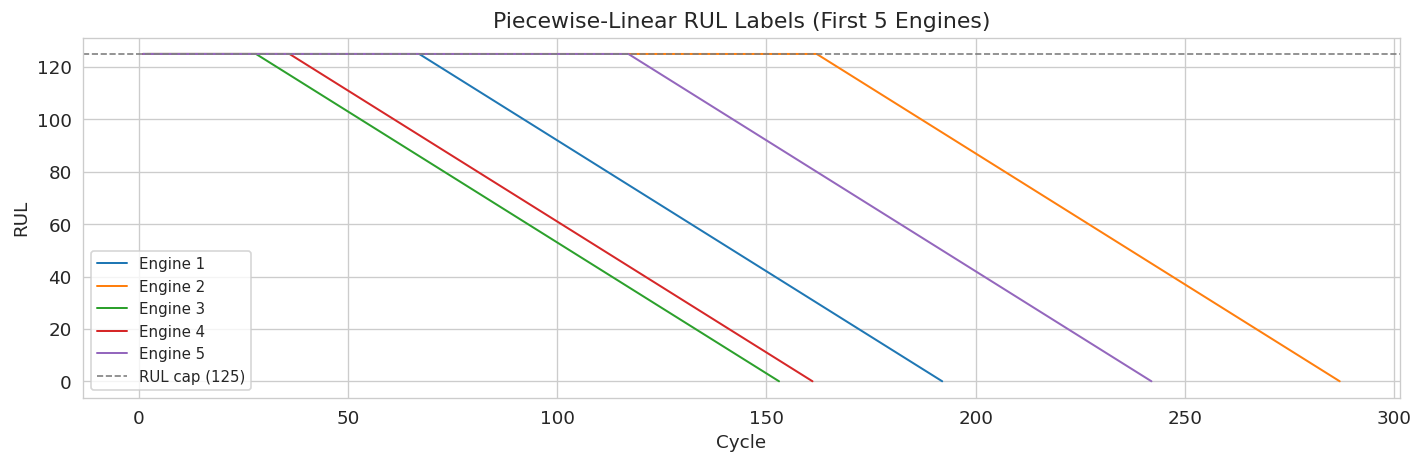

In [46]:
RUL_CAP = 125

max_cycles = train_clean.groupby('unit_id')['cycle'].max().reset_index()
max_cycles.columns = ['unit_id', 'max_cycle']
train_clean = train_clean.merge(max_cycles, on='unit_id', how='left')
train_clean['RUL'] = (train_clean['max_cycle'] - train_clean['cycle']).clip(upper=RUL_CAP)
train_clean.drop(columns=['max_cycle'], inplace=True)

# Plot RUL curve for a few engines
fig, ax = plt.subplots(figsize=(12, 4))
for uid in [1, 2, 3, 4, 5]:
    eng = train_clean[train_clean['unit_id'] == uid]
    ax.plot(eng['cycle'], eng['RUL'], label=f'Engine {uid}', linewidth=1.2)
ax.axhline(RUL_CAP, color='gray', linestyle='--', linewidth=1, label=f'RUL cap ({RUL_CAP})')
ax.set(title='Piecewise-Linear RUL Labels (First 5 Engines)',
       xlabel='Cycle', ylabel='RUL')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('rul_labels.png', bbox_inches='tight')
plt.show()

---
## 6. Standardisation (Z-score)

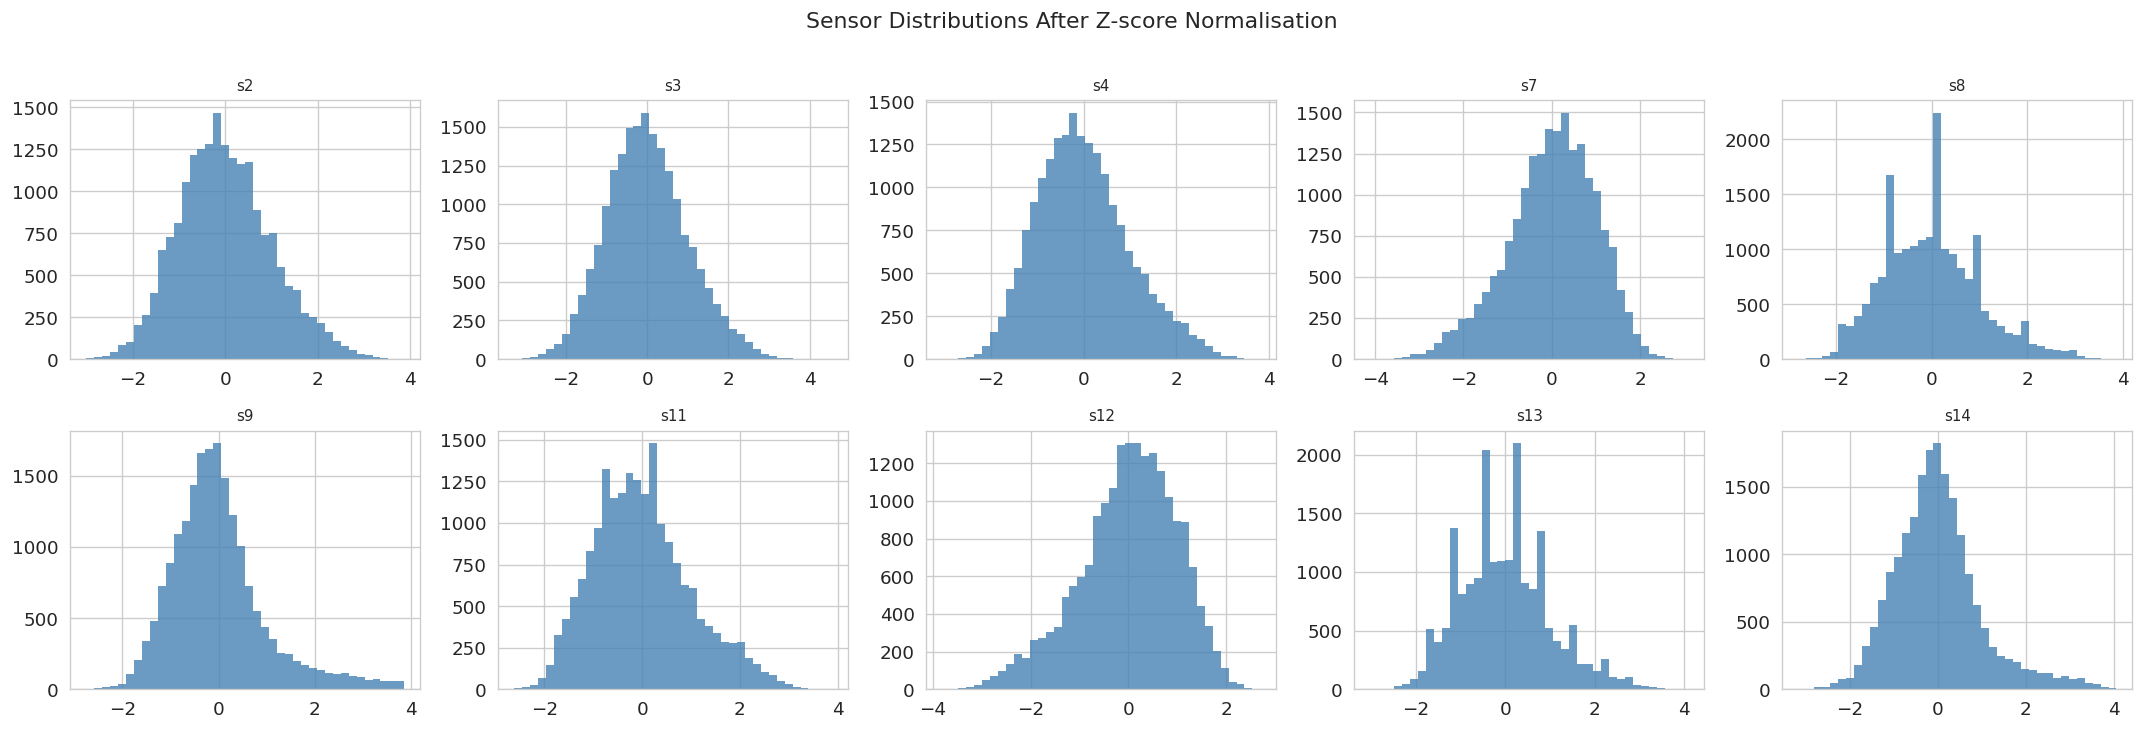

In [47]:
scaler = StandardScaler()
train_clean[selected_sensors] = scaler.fit_transform(train_clean[selected_sensors])

# Apply same scaler to test set
test_df[selected_sensors] = scaler.transform(test_df[selected_sensors])

# Confirm distribution after scaling
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, col in zip(axes.flatten(), selected_sensors[:10]):
    ax.hist(train_clean[col], bins=40, color='steelblue', edgecolor='none', alpha=0.8)
    ax.set_title(col, fontsize=9)
plt.suptitle('Sensor Distributions After Z-score Normalisation', y=1.01)
plt.tight_layout()

plt.savefig('normalised_distributions.png', bbox_inches='tight')
plt.show()

---
## 7. Time-Series Structuring & Sliding Window Generation

X_train shape : (16507, 30, 14)  (windows, timesteps, sensors)
y_train shape : (16507,)


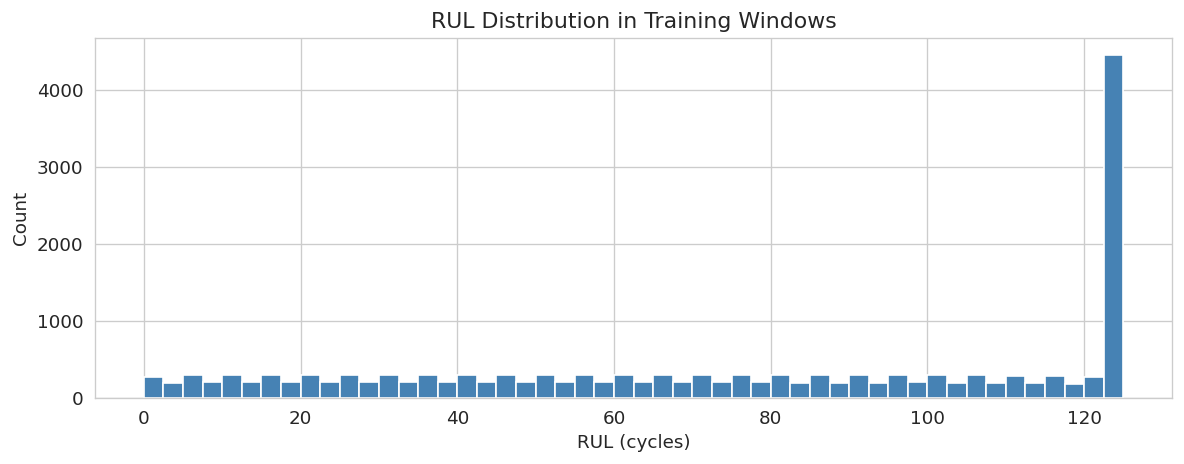

In [48]:
def create_sliding_windows(df, sensor_cols, window_size=30, step=1):
    """
    Creates sliding windows from per-engine time series.
    Returns:
        X_windows : shape (N, window_size, n_sensors)
        y_rul     : shape (N,) — RUL at the last cycle of each window
        unit_ids  : shape (N,) — which engine each window belongs to
    """
    X_list, y_list, uid_list = [], [], []
    for uid, grp in df.groupby('unit_id'):
        grp = grp.sort_values('cycle')
        data   = grp[sensor_cols].values
        labels = grp['RUL'].values
        for start in range(0, len(data) - window_size + 1, step):
            end = start + window_size
            X_list.append(data[start:end])
            y_list.append(labels[end - 1])
            uid_list.append(uid)
    return (np.array(X_list),
            np.array(y_list),
            np.array(uid_list))

WINDOW_SIZE = 30
X_train, y_train, uid_train = create_sliding_windows(
    train_clean, selected_sensors, window_size=WINDOW_SIZE)

print(f'X_train shape : {X_train.shape}  (windows, timesteps, sensors)')
print(f'y_train shape : {y_train.shape}')

# RUL label distribution in windows
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(y_train, bins=50, color='steelblue', edgecolor='white')
ax.set(title='RUL Distribution in Training Windows',
       xlabel='RUL (cycles)', ylabel='Count')
plt.tight_layout()
plt.savefig('rul_distribution_windows.png', bbox_inches='tight')
plt.show()

---
## 8. Dimensionality Reduction — PCA

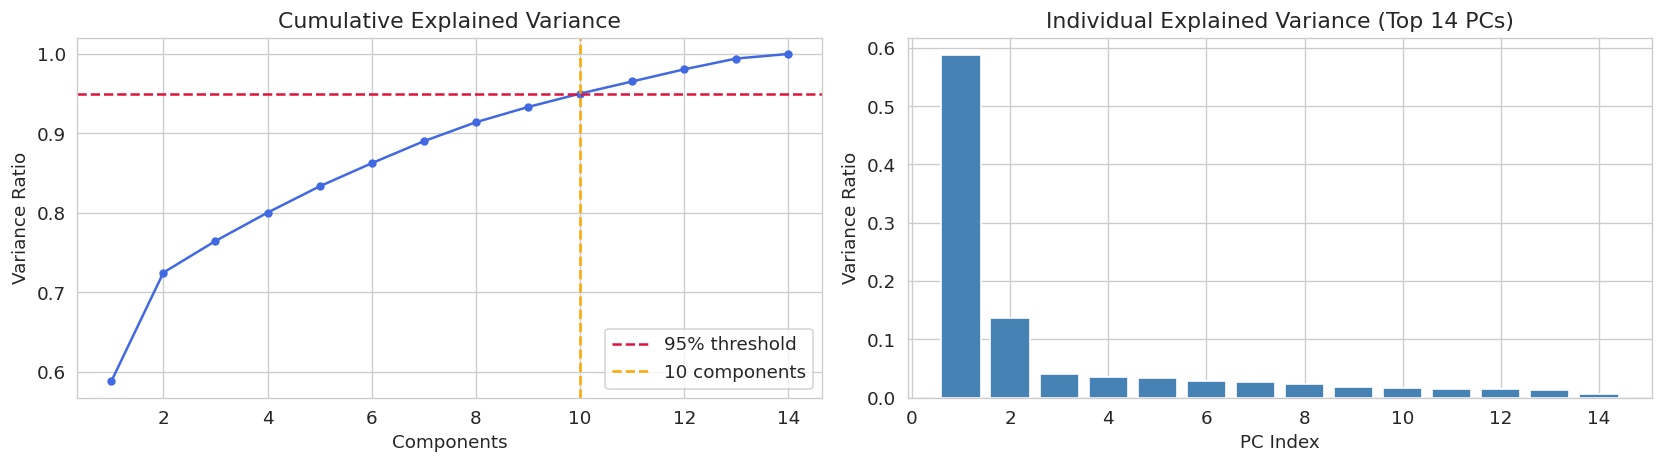

Components needed for 95% variance : 10


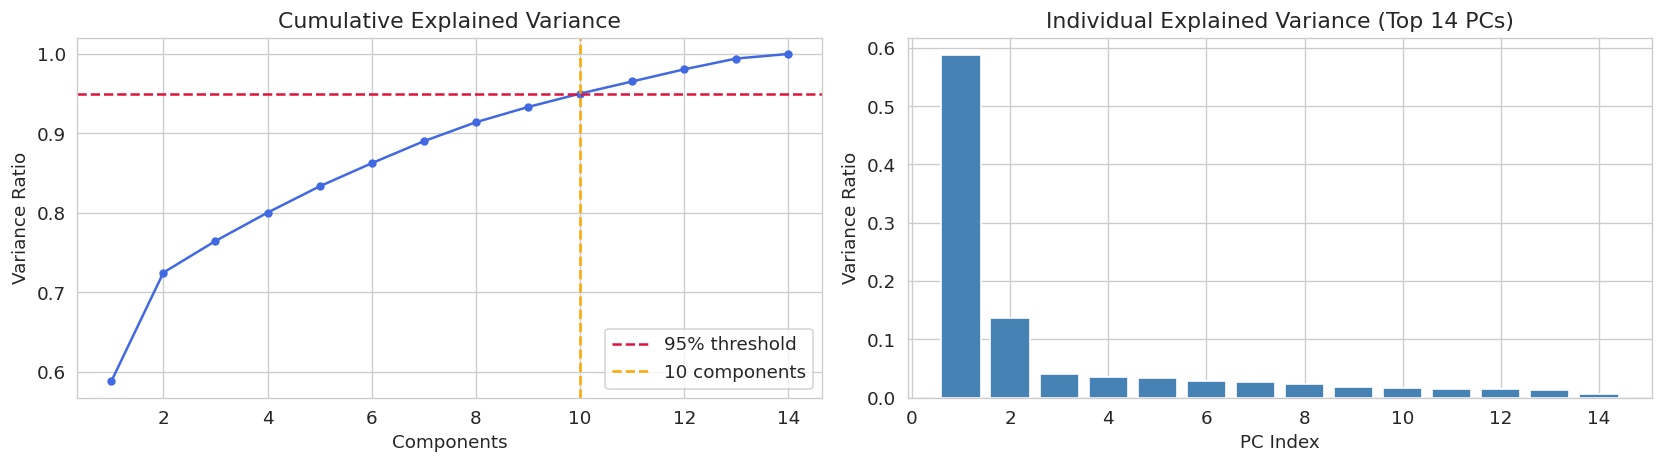

Components needed for 95% variance : 10
pca object created successfully.
X_pca_train shape : (16507, 30, 10)


In [49]:
# PCA Explained Variance
N, T, F = X_train.shape
X_flat = X_train.reshape(-1, F)

pca_full = PCA()
pca_full.fit(X_flat)
cum_var      = np.cumsum(pca_full.explained_variance_ratio_)
n_components = int(np.argmax(cum_var >= 0.95)) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left plot — cumulative variance
axes[0].plot(range(1, len(cum_var)+1), cum_var, 'o-', color='royalblue', ms=4)
axes[0].axhline(0.95, color='crimson', linestyle='--', label='95% threshold')
axes[0].axvline(n_components, color='orange', linestyle='--',
                label=f'{n_components} components')
axes[0].set(title='Cumulative Explained Variance',
            xlabel='Components', ylabel='Variance Ratio')
axes[0].legend()

# Right plot — individual variance
n_show_bars = min(len(pca_full.explained_variance_ratio_), 15)
axes[1].bar(range(1, n_show_bars + 1),
            pca_full.explained_variance_ratio_[:n_show_bars],
            color='steelblue', edgecolor='white')
axes[1].set(title=f'Individual Explained Variance (Top {n_show_bars} PCs)',
            xlabel='PC Index', ylabel='Variance Ratio')

plt.tight_layout()
plt.savefig('pca_explained_variance.png', bbox_inches='tight')
plt.show();

print(f'Components needed for 95% variance : {n_components}')

N, T, F = X_train.shape
X_flat = X_train.reshape(-1, F)

pca_full = PCA()
pca_full.fit(X_flat)
cum_var      = np.cumsum(pca_full.explained_variance_ratio_)
n_components = int(np.argmax(cum_var >= 0.95)) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(range(1, len(cum_var)+1), cum_var, 'o-', color='royalblue', ms=4)
axes[0].axhline(0.95, color='crimson', linestyle='--', label='95% threshold')
axes[0].axvline(n_components, color='orange', linestyle='--',
                label=f'{n_components} components')
axes[0].set(title='Cumulative Explained Variance',
            xlabel='Components', ylabel='Variance Ratio')
axes[0].legend()

n_show_bars = min(len(pca_full.explained_variance_ratio_), 15)
axes[1].bar(range(1, n_show_bars + 1),
            pca_full.explained_variance_ratio_[:n_show_bars],
            color='steelblue', edgecolor='white')
axes[1].set(title=f'Individual Explained Variance (Top {n_show_bars} PCs)',
            xlabel='PC Index', ylabel='Variance Ratio')

plt.tight_layout()
plt.savefig('pca_explained_variance.png', bbox_inches='tight')
plt.show();

print(f'Components needed for 95% variance : {n_components}')

# fit the actual pca object 
pca = PCA(n_components=n_components)
pca.fit(X_flat)
X_pca_train = pca.transform(X_flat).reshape(N, T, n_components)

print(f'pca object created successfully.')
print(f'X_pca_train shape : {X_pca_train.shape}')

---
## 9. Health State Labelling
Map RUL to discrete health states for HMM supervision

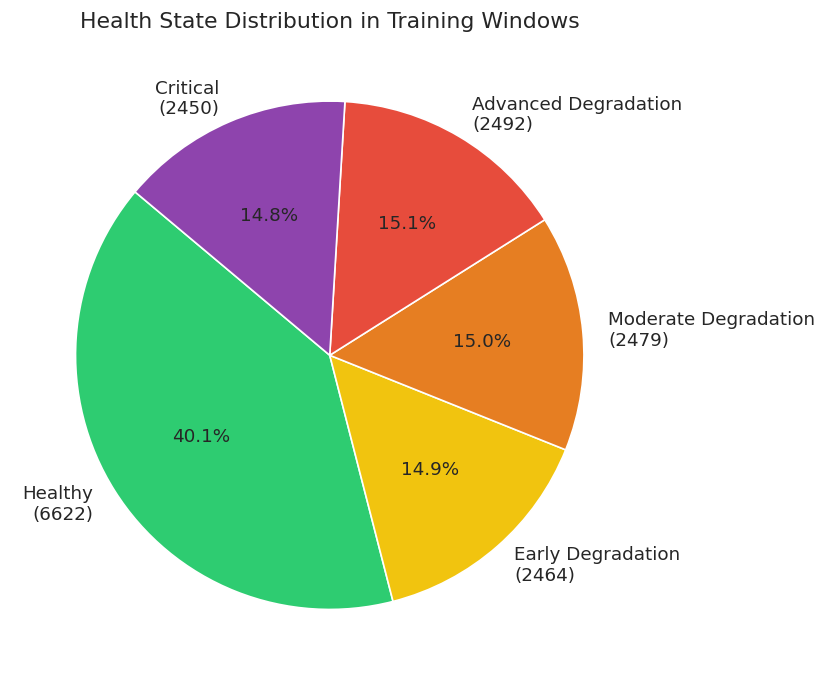


Bin boundaries (RUL): [  0.  25.  50.  75. 100. 125.]
  State 0 (Healthy): 6622 windows
  State 1 (Early Degradation): 2464 windows
  State 2 (Moderate Degradation): 2479 windows
  State 3 (Advanced Degradation): 2492 windows
  State 4 (Critical): 2450 windows


In [50]:
N_STATES = 5  # Adjustable: 3–6 states typical for turbofan PHM

STATE_LABELS = {
    0: 'Healthy',
    1: 'Early Degradation',
    2: 'Moderate Degradation',
    3: 'Advanced Degradation',
    4: 'Critical'
}
STATE_COLORS = ['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c', '#8e44ad']

# Equal-width RUL bins → health state
rul_bins = np.linspace(0, RUL_CAP, N_STATES + 1)

def rul_to_state(rul, bins=rul_bins, n_states=N_STATES):
    """Convert RUL scalar to discrete health state (0=critical, 4=healthy)."""
    state = np.searchsorted(bins, rul, side='right') - 1
    return int(np.clip(n_states - 1 - state, 0, n_states - 1))

health_states = np.array([rul_to_state(r) for r in y_train])

# State distribution pie chart
from collections import Counter
counts = Counter(health_states)
fig, ax = plt.subplots(figsize=(7, 7))
labels = [f'{STATE_LABELS[k]}\n({v})' for k, v in sorted(counts.items())]
sizes  = [counts[k] for k in sorted(counts)]
ax.pie(sizes, labels=labels, colors=[STATE_COLORS[k] for k in sorted(counts)],
       autopct='%1.1f%%', startangle=140)
ax.set_title('Health State Distribution in Training Windows')
plt.tight_layout()
plt.savefig('health_state_distribution.png', bbox_inches='tight')
plt.show()

print('\nBin boundaries (RUL):', np.round(rul_bins, 1))
for s, lbl in STATE_LABELS.items():
    print(f'  State {s} ({lbl}): {counts[s]} windows')

---
## 10. HMM Model Design — Adaptive Left-Right Topology



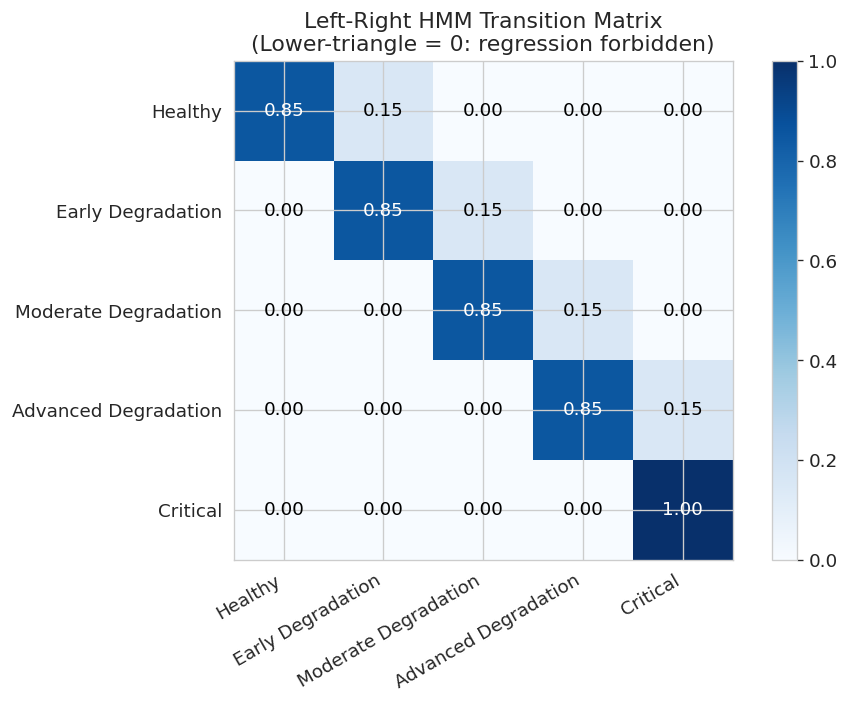

In [51]:
def make_left_right_transmat(n_states, self_loop_prob=0.8):
    """
    Builds a strictly Left-Right (Bakis) transition matrix.
    - Diagonal  : self_loop_prob  (probability of staying in current state)
    - Superdiag : 1 - self_loop_prob  (probability of advancing to next state)
    - Below diag: 0  (regression FORBIDDEN — physical constraint)
    Last state is absorbing (self-loop = 1.0).
    """
    T = np.zeros((n_states, n_states))
    for i in range(n_states - 1):
        T[i, i]   = self_loop_prob
        T[i, i+1] = 1.0 - self_loop_prob
    T[-1, -1] = 1.0  # absorbing critical state
    return T

transmat_init = make_left_right_transmat(N_STATES, self_loop_prob=0.85)

# Visualise the topology
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(transmat_init, cmap='Blues', vmin=0, vmax=1)
for i in range(N_STATES):
    for j in range(N_STATES):
        ax.text(j, i, f'{transmat_init[i,j]:.2f}',
                ha='center', va='center',
                color='black' if transmat_init[i,j] < 0.5 else 'white', fontsize=11)
ax.set_xticks(range(N_STATES))
ax.set_yticks(range(N_STATES))
ax.set_xticklabels([STATE_LABELS[i] for i in range(N_STATES)], rotation=30, ha='right')
ax.set_yticklabels([STATE_LABELS[i] for i in range(N_STATES)])
ax.set_title('Left-Right HMM Transition Matrix\n(Lower-triangle = 0: regression forbidden)')
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig('hmm_transition_matrix.png', bbox_inches='tight')
plt.show()

---
## 11. HMM Training (Expectation-Maximisation)

In [52]:
# Prepare HMM training sequences 
# hmmlearn expects a concatenated 2D array + lengths list
# We use the per-engine full sequence to preserve continuity (not sliding window)

def build_hmm_sequences(df, sensor_pca_cols, pca_transformer, scaler_transformer=None):
    """
    For each engine, extract sorted cycles, apply PCA, return sequences + lengths.
    """
    seqs, lengths = [], []
    for uid, grp in df.groupby('unit_id'):
        grp = grp.sort_values('cycle')
        raw = grp[selected_sensors].values  # already scaled
        pca_seq = pca_transformer.transform(raw)  # (T, n_components)
        seqs.append(pca_seq)
        lengths.append(len(pca_seq))
    return np.vstack(seqs), lengths

X_hmm_train, train_lengths = build_hmm_sequences(train_clean, selected_sensors, pca)
print(f'HMM training data shape : {X_hmm_train.shape}')
print(f'Number of sequences     : {len(train_lengths)}')
print(f'Sequence length range   : {min(train_lengths)} – {max(train_lengths)}')

HMM training data shape : (19407, 10)
Number of sequences     : 100
Sequence length range   : 128 – 358


In [53]:
class LeftRightGaussianHMM(hmm.GaussianHMM):
    def __init__(self, n_components, self_loop_prob=0.85, **kwargs):
        super().__init__(n_components=n_components, **kwargs)
        self.self_loop_prob = self_loop_prob

    def _do_mstep(self, stats):
        super()._do_mstep(stats)
        T = np.triu(self.transmat_.copy())
        row_sums = T.sum(axis=1, keepdims=True)
        row_sums[row_sums == 0] = 1e-12
        self.transmat_ = T / row_sums

model = LeftRightGaussianHMM(
    n_components    = N_STATES,
    self_loop_prob  = 0.85,
    covariance_type = 'full',
    n_iter          = 150,
    tol             = 1e-4,
    verbose         = True,
    init_params     = 'mc',   
    params          = 'mc',   
    random_state    = 42
)

# Now these assignments are respected
model.transmat_  = make_left_right_transmat(N_STATES, self_loop_prob=0.85)
model.startprob_ = np.array([1.0] + [0.0]*(N_STATES-1))

print('Training HMM via Expectation-Maximisation ...')
model.fit(X_hmm_train, train_lengths)
print(f'\nLog-likelihood: {model.score(X_hmm_train, train_lengths):.2f}')

Training HMM via Expectation-Maximisation ...


         1 -203794.80571905             +nan
         2 -190659.53867045  +13135.26704860
         3 -188670.74609804   +1988.79257241
         4 -187084.55430069   +1586.19179735
         5 -186248.75939042    +835.79491028
         6 -186112.97879564    +135.78059477
         7 -186041.70055978     +71.27823586
         8 -186000.86948353     +40.83107625
         9 -185988.68955895     +12.17992457
        10 -185983.10276908      +5.58678987
        11 -185980.70472534      +2.39804374
        12 -185979.59446587      +1.11025947
        13 -185978.87935463      +0.71511124
        14 -185978.35120655      +0.52814809
        15 -185977.97916770      +0.37203884
        16 -185977.73289442      +0.24627328
        17 -185977.56830758      +0.16458685
        18 -185977.45141000      +0.11689757
        19 -185977.36380681      +0.08760319
        20 -185977.29663362      +0.06717319
        21 -185977.24521996      +0.05141366
        22 -185977.20647907      +0.03874089
        23


Log-likelihood: -185977.11


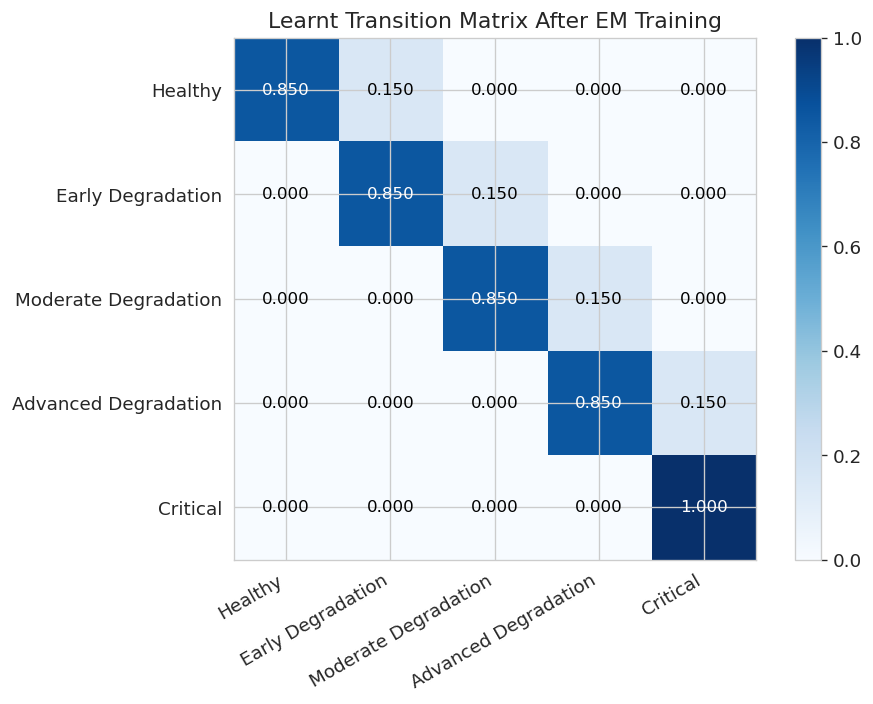

In [54]:
# Learnt transition matrix 
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(model.transmat_, cmap='Blues', vmin=0, vmax=1)
for i in range(N_STATES):
    for j in range(N_STATES):
        ax.text(j, i, f'{model.transmat_[i,j]:.3f}',
                ha='center', va='center',
                color='black' if model.transmat_[i,j] < 0.5 else 'white', fontsize=10)
ax.set_xticks(range(N_STATES))
ax.set_yticks(range(N_STATES))
ax.set_xticklabels([STATE_LABELS[i] for i in range(N_STATES)], rotation=30, ha='right')
ax.set_yticklabels([STATE_LABELS[i] for i in range(N_STATES)])
ax.set_title('Learnt Transition Matrix After EM Training')
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig('learned_transition_matrix.png', bbox_inches='tight')
plt.show()

---
## 12. RUL Estimation
Expected RUL = Σ state × P(state | observations)

In [55]:
# Map state index to expected RUL using bin midpoints
bin_midpoints = [(rul_bins[i] + rul_bins[i+1]) / 2 for i in range(N_STATES)]
# Reverse: state 0 = Healthy = high RUL, state N-1 = Critical = low RUL
state_to_rul = {s: bin_midpoints[N_STATES - 1 - s] for s in range(N_STATES)}
print('State → Expected RUL mapping:')
for s, rul in state_to_rul.items():
    print(f'  State {s} ({STATE_LABELS[s]}) → {rul:.1f} cycles')


def predict_rul_for_engine(engine_df, model, pca_transformer, state_to_rul,
                            selected_sensors, n_states=None):
    if n_states is None:
        n_states = model.n_components   # ← always read from model, not global
    grp     = engine_df.sort_values('cycle')
    raw     = grp[selected_sensors].values
    pca_seq = pca_transformer.transform(raw)
    _, state_seq = model.decode(pca_seq, algorithm='viterbi')
    posteriors   = model.predict_proba(pca_seq)
    rul_weights  = np.array([state_to_rul[s] for s in range(n_states)])
    rul_pred     = posteriors @ rul_weights
    return rul_pred, state_seq, posteriors

State → Expected RUL mapping:
  State 0 (Healthy) → 112.5 cycles
  State 1 (Early Degradation) → 87.5 cycles
  State 2 (Moderate Degradation) → 62.5 cycles
  State 3 (Advanced Degradation) → 37.5 cycles
  State 4 (Critical) → 12.5 cycles


In [56]:
# Predict on entire training set (per engine)
all_preds, all_true = [], []

for uid, grp in train_clean.groupby('unit_id'):
    rul_pred, _, _ = predict_rul_for_engine(grp, model, pca, state_to_rul, selected_sensors)
    rul_true = grp.sort_values('cycle')['RUL'].values
    all_preds.extend(rul_pred.tolist())
    all_true.extend(rul_true.tolist())

all_preds = np.array(all_preds)
all_true  = np.array(all_true)

rmse_train = np.sqrt(mean_squared_error(all_true, all_preds))
mae_train  = mean_absolute_error(all_true, all_preds)
print(f'Train RMSE : {rmse_train:.2f}')
print(f'Train MAE  : {mae_train:.2f}')

Train RMSE : 30.24
Train MAE  : 24.16


---
## 13. Performance Evaluation on Training Data

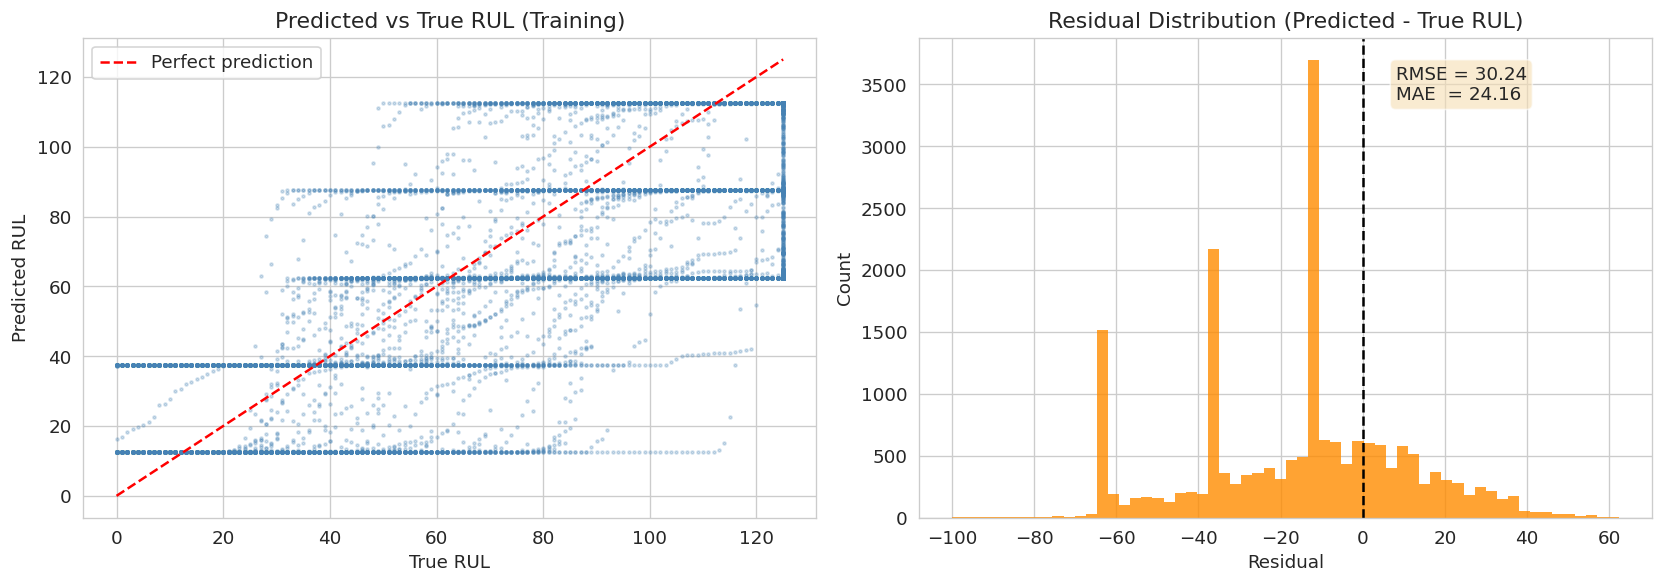

In [57]:
# Scatter plot: Predicted vs True RUL 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(all_true, all_preds, s=3, alpha=0.25, color='steelblue')
lim = max(all_true.max(), all_preds.max())
axes[0].plot([0, lim], [0, lim], 'r--', linewidth=1.5, label='Perfect prediction')
axes[0].set(title='Predicted vs True RUL (Training)',
            xlabel='True RUL', ylabel='Predicted RUL')
axes[0].legend()

# Residual distribution
residuals = all_preds - all_true
axes[1].hist(residuals, bins=60, color='darkorange', edgecolor='none', alpha=0.8)
axes[1].axvline(0, color='black', linewidth=1.5, linestyle='--')
axes[1].set(title='Residual Distribution (Predicted - True RUL)',
            xlabel='Residual', ylabel='Count')
axes[1].text(0.65, 0.87, f'RMSE = {rmse_train:.2f}\nMAE  = {mae_train:.2f}',
             transform=axes[1].transAxes, fontsize=11,
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.6))

plt.tight_layout()
plt.savefig('train_evaluation.png', bbox_inches='tight')
plt.show()

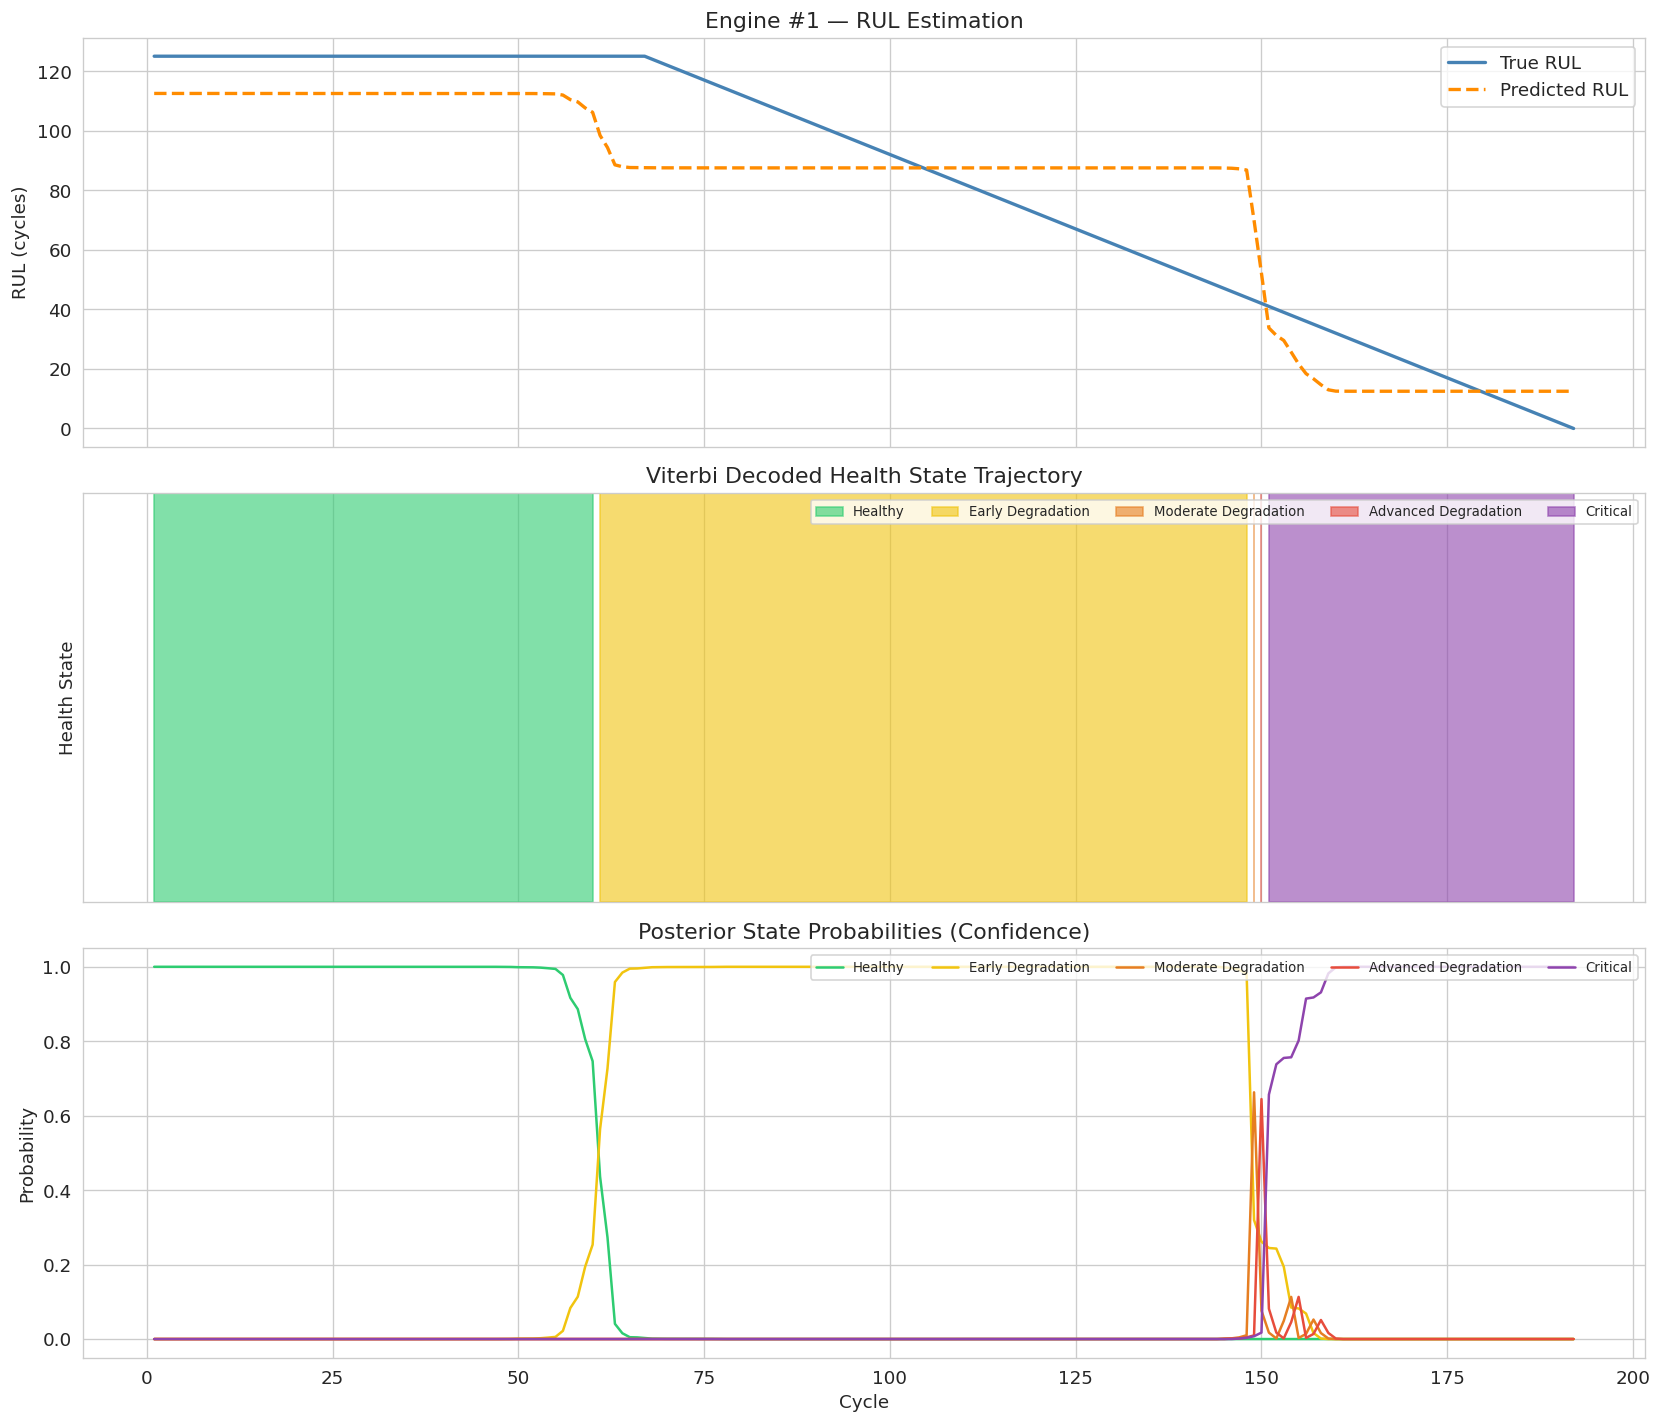

In [58]:
# Health state trajectory for a single engine (training)
DEMO_ENGINE = 1
grp = train_clean[train_clean['unit_id'] == DEMO_ENGINE].sort_values('cycle')
rul_pred_demo, state_seq_demo, posteriors_demo = predict_rul_for_engine(
    grp, model, pca, state_to_rul, selected_sensors)
rul_true_demo = grp['RUL'].values
cycles_demo   = grp['cycle'].values

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# (a) RUL comparison
axes[0].plot(cycles_demo, rul_true_demo, label='True RUL', color='steelblue', linewidth=2)
axes[0].plot(cycles_demo, rul_pred_demo, label='Predicted RUL', color='darkorange',
             linewidth=2, linestyle='--')
axes[0].set(title=f'Engine #{DEMO_ENGINE} — RUL Estimation', ylabel='RUL (cycles)')
axes[0].legend()

# (b) State sequence
for s in range(N_STATES):
    axes[1].fill_between(cycles_demo,
                         0, 1,
                         where=(state_seq_demo == s),
                         alpha=0.6, color=STATE_COLORS[s],
                         label=STATE_LABELS[s])
axes[1].set(title='Viterbi Decoded Health State Trajectory', ylabel='Health State', ylim=(0,1))
axes[1].set_yticks([])
axes[1].legend(loc='upper right', ncol=N_STATES, fontsize=8)

# (c) State posterior probabilities
for s in range(N_STATES):
    axes[2].plot(cycles_demo, posteriors_demo[:, s],
                 color=STATE_COLORS[s], label=STATE_LABELS[s], linewidth=1.5)
axes[2].set(title='Posterior State Probabilities (Confidence)',
            xlabel='Cycle', ylabel='Probability')
axes[2].legend(fontsize=8, ncol=N_STATES, loc='upper right')

plt.tight_layout()
plt.savefig('engine_health_trajectory.png', bbox_inches='tight')
plt.show()

---
## 14. NASA Scoring Function
The asymmetric scoring function penalises late predictions more than early ones.

In [59]:
def nasa_score(y_true, y_pred):
    """NASA CMAPSS scoring function — asymmetric penalty."""
    diff = y_pred - y_true
    score = np.where(diff < 0,
                     np.exp(-diff / 13.0) - 1,
                     np.exp( diff / 10.0) - 1)
    return score.sum()

train_nasa = nasa_score(all_true, all_preds)
print(f'NASA Score (training, lower is better): {train_nasa:.2f}')

NASA Score (training, lower is better): 427279.91


---
## 15. Hyperparameter Optimisation — Grid Search on N_STATES

State grid search: 100%|████████████████████████████████████████████| 5/5 [00:20<00:00,  4.00s/it]



Grid Search Results:
N_STATES     RMSE         MAE          NASA Score  
------------------------------------------------
3            38.93        29.55        4151973.84  
4            42.54        33.55        2364527.45  
5            30.50        24.37        437351.65   
6            30.97        24.01        515144.18   
7            39.39        30.90        1944561.56  


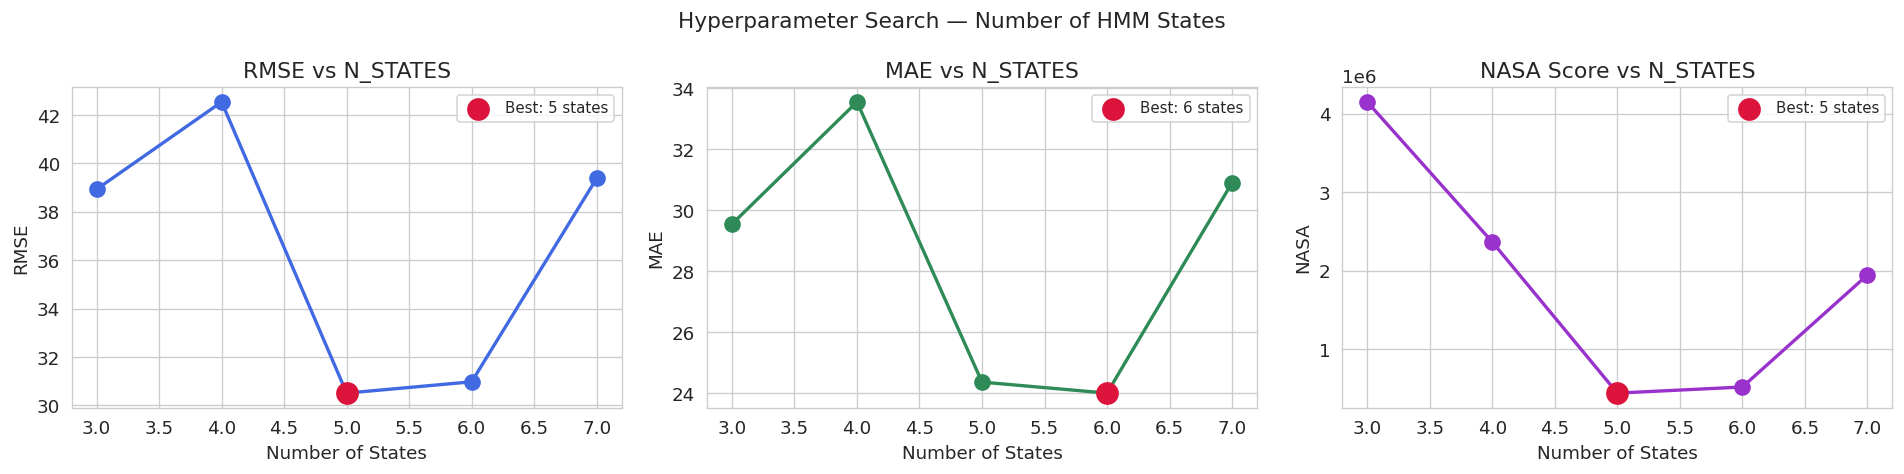


Best N_STATES by RMSE : 5
Best RMSE             : 30.50


In [60]:
state_options = [3, 4, 5, 6, 7]
rmse_scores, mae_scores, nasa_scores_list = [], [], []

for n_s in tqdm(state_options, desc='State grid search'):
    bins_tmp = np.linspace(0, RUL_CAP, n_s + 1)
    mids_tmp = [(bins_tmp[i]+bins_tmp[i+1])/2 for i in range(n_s)]
    s2r_tmp  = {s: mids_tmp[n_s-1-s] for s in range(n_s)}

    m_tmp = LeftRightGaussianHMM(
        n_components    = n_s,
        covariance_type = 'full',
        n_iter          = 50,
        tol             = 1e-3,
        init_params     = 'mc',
        params          = 'mc',
        random_state    = 42
    )
    m_tmp.transmat_  = make_left_right_transmat(n_s)
    m_tmp.startprob_ = np.array([1.0] + [0.0]*(n_s-1))
    m_tmp.fit(X_hmm_train, train_lengths)

    preds_tmp, true_tmp = [], []
    for uid, grp in train_clean.groupby('unit_id'):
        rp, _, _ = predict_rul_for_engine(
            grp, m_tmp, pca, s2r_tmp, selected_sensors)
        preds_tmp.extend(rp.tolist())
        true_tmp.extend(grp.sort_values('cycle')['RUL'].values.tolist())

    preds_tmp = np.array(preds_tmp)
    true_tmp  = np.array(true_tmp)
    rmse_scores.append(np.sqrt(mean_squared_error(true_tmp, preds_tmp)))
    mae_scores.append(mean_absolute_error(true_tmp, preds_tmp))
    nasa_scores_list.append(nasa_score(true_tmp, preds_tmp))

# Print results table 
print('\nGrid Search Results:')
print(f'{"N_STATES":<12} {"RMSE":<12} {"MAE":<12} {"NASA Score":<12}')
print('-' * 48)
for i, n_s in enumerate(state_options):
    print(f'{n_s:<12} {rmse_scores[i]:<12.2f} {mae_scores[i]:<12.2f} {nasa_scores_list[i]:<12.2f}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, vals, title, color in zip(
        axes,
        [rmse_scores, mae_scores, nasa_scores_list],
        ['RMSE vs N_STATES', 'MAE vs N_STATES', 'NASA Score vs N_STATES'],
        ['royalblue', 'seagreen', 'darkorchid']):
    ax.plot(state_options, vals, 'o-', color=color, ms=9, linewidth=2)
    bi = int(np.argmin(vals))
    ax.scatter([state_options[bi]], [vals[bi]], s=160, color='crimson',
               zorder=5, label=f'Best: {state_options[bi]} states')
    ax.set(title=title, xlabel='Number of States', ylabel=title.split(' ')[0])
    ax.legend(fontsize=9)
plt.suptitle('Hyperparameter Search — Number of HMM States', fontsize=13)
plt.tight_layout()
plt.savefig('hyperparameter_search.png', bbox_inches='tight')
plt.show();

# ── Set best_n_states ─────────────────────────────────────────────────────────
best_n_states = state_options[int(np.argmin(rmse_scores))]
print(f'\nBest N_STATES by RMSE : {best_n_states}')
print(f'Best RMSE             : {min(rmse_scores):.2f}')

---
## 16. Fine-Tuned Model (Best N_STATES)

In [61]:
N_STATES_BEST = best_n_states
rul_bins_best = np.linspace(0, RUL_CAP, N_STATES_BEST + 1)
bin_mid_best  = [(rul_bins_best[i]+rul_bins_best[i+1])/2 for i in range(N_STATES_BEST)]
s2r_best      = {s: bin_mid_best[N_STATES_BEST-1-s] for s in range(N_STATES_BEST)}

model_best = LeftRightGaussianHMM(
    n_components    = N_STATES_BEST,
    covariance_type = 'full',
    n_iter          = 200,
    tol             = 1e-5,
    random_state    = 42
)
model_best.transmat_  = make_left_right_transmat(N_STATES_BEST)
model_best.startprob_ = np.array([1.0]+[0.0]*(N_STATES_BEST-1))

print(f'Training fine-tuned model with {N_STATES_BEST} states ...')
model_best.fit(X_hmm_train, train_lengths)
print('Done.')

Even though the 'startprob_' attribute is set, it will be overwritten during initialization because 'init_params' contains 's'
Even though the 'transmat_' attribute is set, it will be overwritten during initialization because 'init_params' contains 't'


Training fine-tuned model with 5 states ...


Model is not converging.  Current: -187614.1669994823 is not greater than -187395.0582104925. Delta is -219.10878898977535


Done.


---
## 17. Test Set Evaluation

In [62]:
# RUL Bias Analysis on Training Set first
train_preds_all, train_true_all = [], []
for uid, grp in train_clean.groupby('unit_id'):
    rp, _, _ = predict_rul_for_engine(grp, model_best, pca, s2r_best, selected_sensors)
    train_preds_all.extend(rp.tolist())
    train_true_all.extend(grp.sort_values('cycle')['RUL'].values.tolist())

train_preds_all = np.array(train_preds_all)
train_true_all  = np.array(train_true_all)

# Compute systematic bias (mean residual on training set)
bias = np.mean(train_true_all - train_preds_all)
print(f'Systematic bias (True - Pred) on training set: {bias:.2f} cycles')
print(f'Applying correction of +{bias:.2f} to all predictions')

# Test Set Prediction WITH bias correction 
pred_final_rul = []
for uid, grp in test_df.groupby('unit_id'):
    grp_sorted  = grp.sort_values('cycle')
    raw         = grp_sorted[selected_sensors].values
    pca_seq     = pca.transform(raw)
    posteriors  = model_best.predict_proba(pca_seq)
    rul_weights = np.array([s2r_best[s] for s in range(N_STATES_BEST)])
    rul_sequence = posteriors @ rul_weights

    # Apply bias correction + clip to valid RUL range
    corrected = np.clip(rul_sequence[-1] + bias, 0, RUL_CAP)
    pred_final_rul.append(corrected)

pred_final_rul = np.array(pred_final_rul)
true_final_rul = rul_df['RUL_true'].values[:len(pred_final_rul)]

rmse_test = np.sqrt(mean_squared_error(true_final_rul, pred_final_rul))
mae_test  = mean_absolute_error(true_final_rul, pred_final_rul)
nasa_test = nasa_score(true_final_rul, pred_final_rul)

print(f'\n=== TEST SET RESULTS (bias-corrected) ===')
print(f'Bias correction applied : +{bias:.2f} cycles')
print(f'RMSE                    : {rmse_test:.4f}')
print(f'MAE                     : {mae_test:.4f}')
print(f'NASA Score              : {nasa_test:.2f}')

Systematic bias (True - Pred) on training set: 19.48 cycles
Applying correction of +19.48 to all predictions

=== TEST SET RESULTS (bias-corrected) ===
Bias correction applied : +19.48 cycles
RMSE                    : 30.1070
MAE                     : 23.4005
NASA Score              : 9993.96


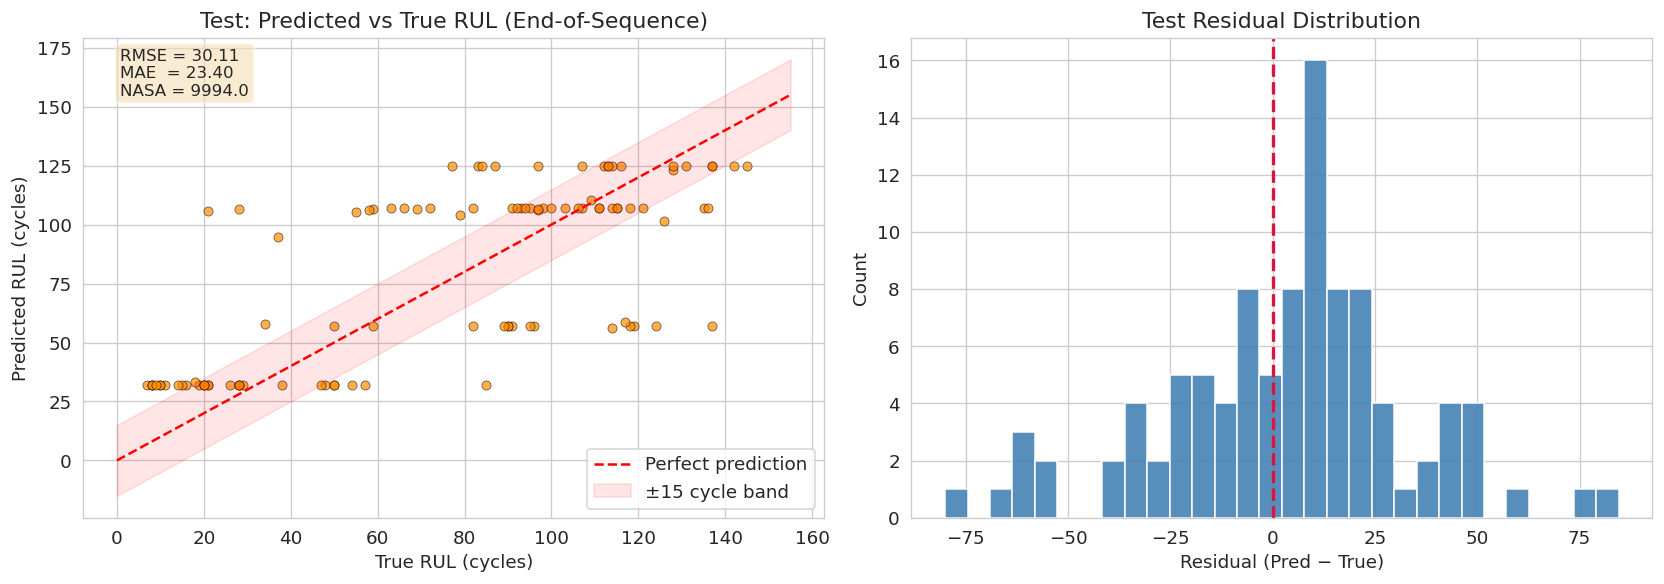

In [63]:
# Test: Predicted vs True scatter 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(true_final_rul, pred_final_rul, s=30, alpha=0.7,
                color='darkorange', edgecolors='black', linewidths=0.4)
lim = max(true_final_rul.max(), pred_final_rul.max()) + 10
axes[0].plot([0, lim], [0, lim], 'r--', linewidth=1.5, label='Perfect prediction')
axes[0].fill_between([0, lim], [0+15, lim+15], [0-15, lim-15],
                      alpha=0.1, color='red', label='±15 cycle band')
axes[0].set(title='Test: Predicted vs True RUL (End-of-Sequence)',
            xlabel='True RUL (cycles)', ylabel='Predicted RUL (cycles)')
axes[0].legend()
axes[0].text(0.05, 0.88,
             f'RMSE = {rmse_test:.2f}\nMAE  = {mae_test:.2f}\nNASA = {nasa_test:.1f}',
             transform=axes[0].transAxes, fontsize=10,
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.6))

# Error distribution
test_residuals = pred_final_rul - true_final_rul
axes[1].hist(test_residuals, bins=30, color='steelblue', edgecolor='white', alpha=0.9)
axes[1].axvline(0, color='crimson', linewidth=2, linestyle='--')
axes[1].set(title='Test Residual Distribution', xlabel='Residual (Pred − True)', ylabel='Count')

plt.tight_layout()
plt.savefig('test_evaluation.png', bbox_inches='tight')
plt.show()

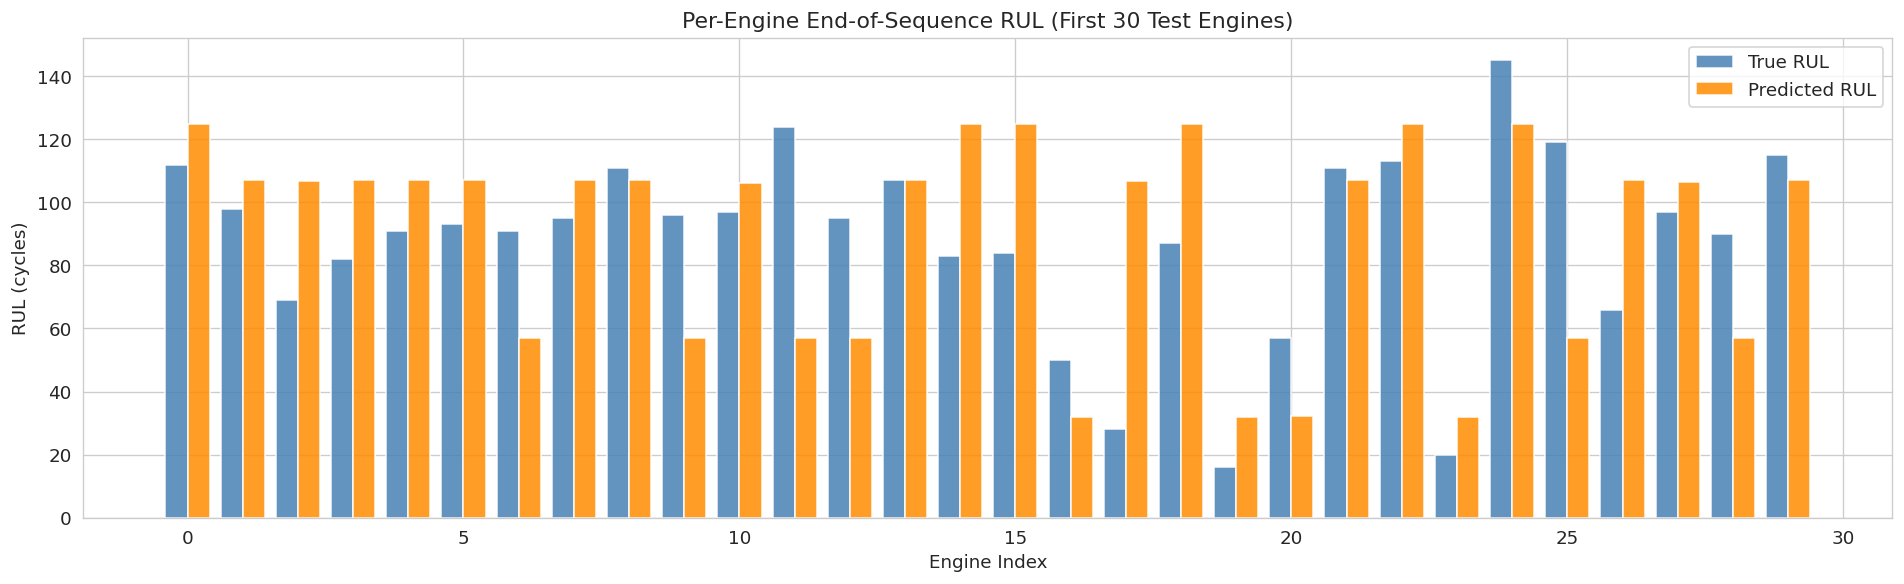

In [64]:
#  Per-engine test RUL bar chart 
n_show = min(30, len(true_final_rul))
indices = np.arange(n_show)

fig, ax = plt.subplots(figsize=(16, 5))
ax.bar(indices - 0.2, true_final_rul[:n_show],  0.4,
       label='True RUL',      color='steelblue',  alpha=0.85)
ax.bar(indices + 0.2, pred_final_rul[:n_show], 0.4,
       label='Predicted RUL', color='darkorange', alpha=0.85)
ax.set(title=f'Per-Engine End-of-Sequence RUL (First {n_show} Test Engines)',
       xlabel='Engine Index', ylabel='RUL (cycles)')
ax.legend()
plt.tight_layout()
plt.savefig('test_per_engine_rul.png', bbox_inches='tight')
plt.show()

---
## 18. Explainability — Health State Dashboard

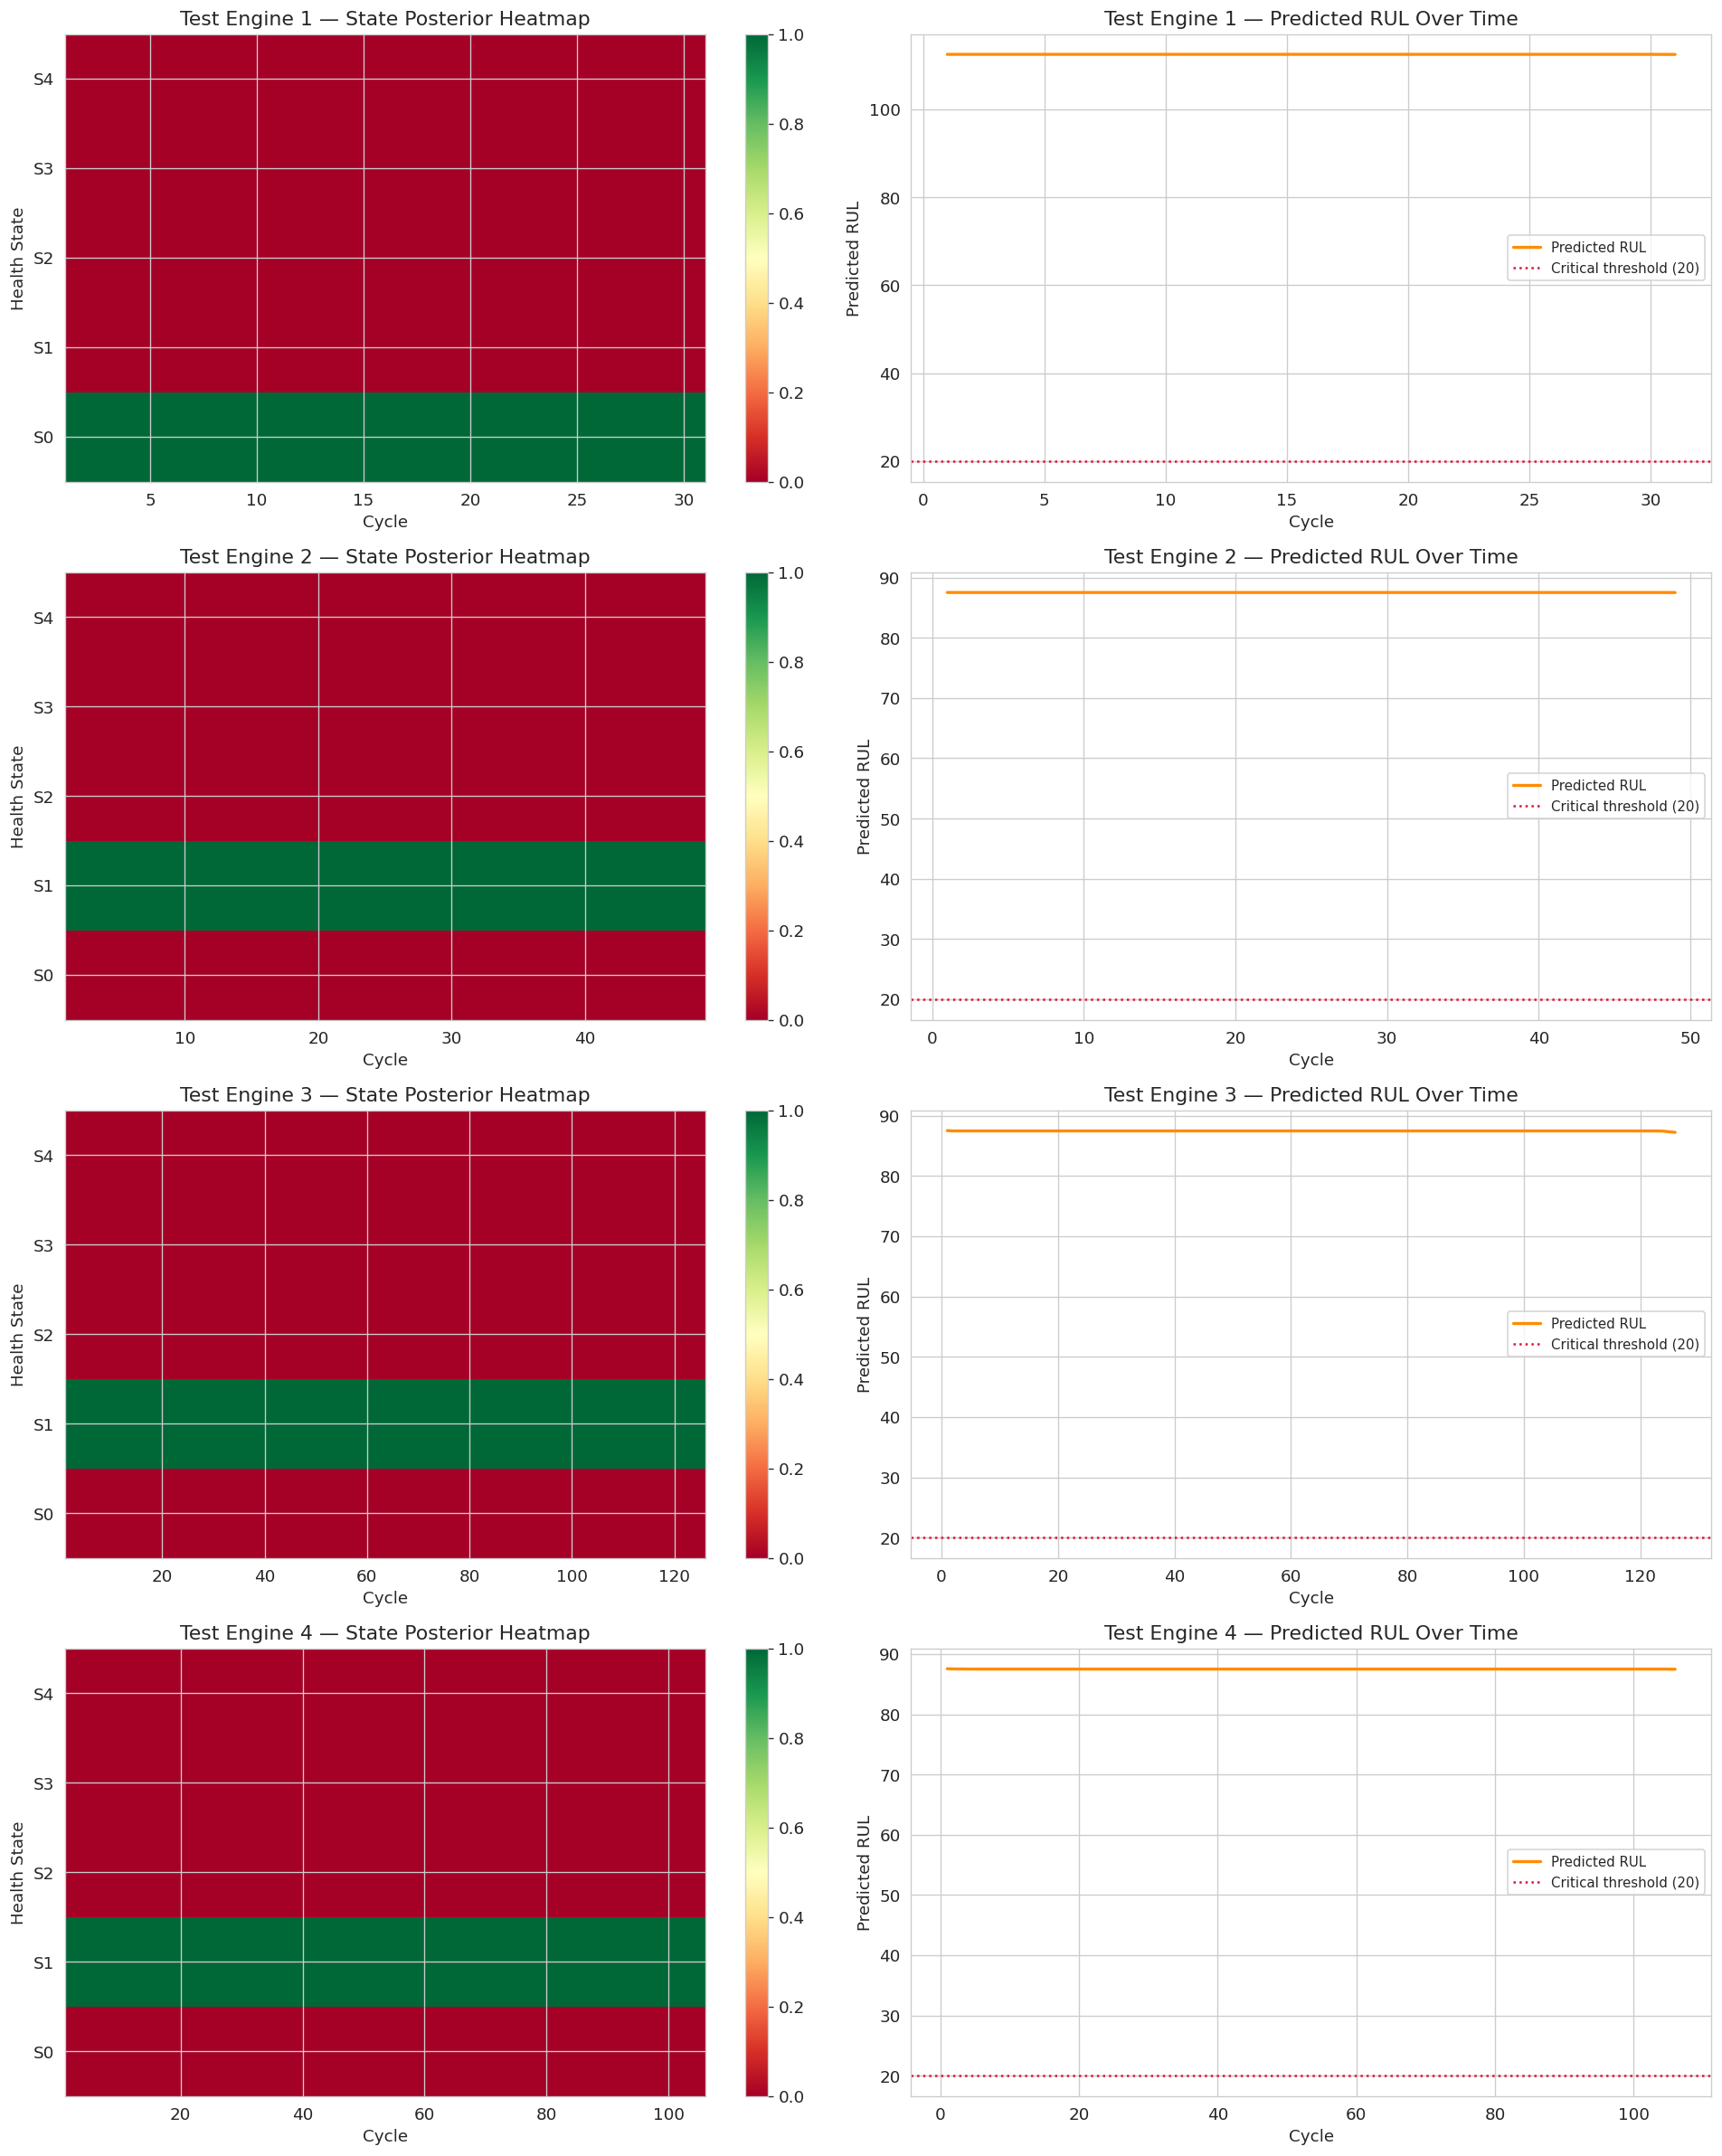

In [65]:
# Full degradation trajectory for 4 test engines
COLORS_BEST = plt.cm.RdYlGn(np.linspace(0.85, 0.1, N_STATES_BEST))

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
for row, uid in enumerate([1, 2, 3, 4]):
    grp = test_df[test_df['unit_id'] == uid].sort_values('cycle')
    raw = grp[selected_sensors].values
    pca_seq = pca.transform(raw)
    posteriors = model_best.predict_proba(pca_seq)
    rul_weights = np.array([s2r_best[s] for s in range(N_STATES_BEST)])
    rul_pred_test = posteriors @ rul_weights
    cycles = grp['cycle'].values

    # Left: Posterior heatmap
    im = axes[row, 0].imshow(posteriors.T, aspect='auto', origin='lower',
                              cmap='RdYlGn', vmin=0, vmax=1,
                              extent=[cycles[0], cycles[-1], -0.5, N_STATES_BEST-0.5])
    axes[row, 0].set(title=f'Test Engine {uid} — State Posterior Heatmap',
                     xlabel='Cycle', ylabel='Health State')
    axes[row, 0].set_yticks(range(N_STATES_BEST))
    axes[row, 0].set_yticklabels([f'S{i}' for i in range(N_STATES_BEST)])
    plt.colorbar(im, ax=axes[row, 0])

    # Right: RUL prediction over time
    axes[row, 1].plot(cycles, rul_pred_test, color='darkorange', linewidth=2, label='Predicted RUL')
    axes[row, 1].axhline(20, color='crimson', linestyle=':', linewidth=1.5, label='Critical threshold (20)')
    axes[row, 1].set(title=f'Test Engine {uid} — Predicted RUL Over Time',
                     xlabel='Cycle', ylabel='Predicted RUL')
    axes[row, 1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('test_health_dashboard.png', bbox_inches='tight')
plt.show()

---
## 19. PCA Biplot — Degradation in Principal Component Space

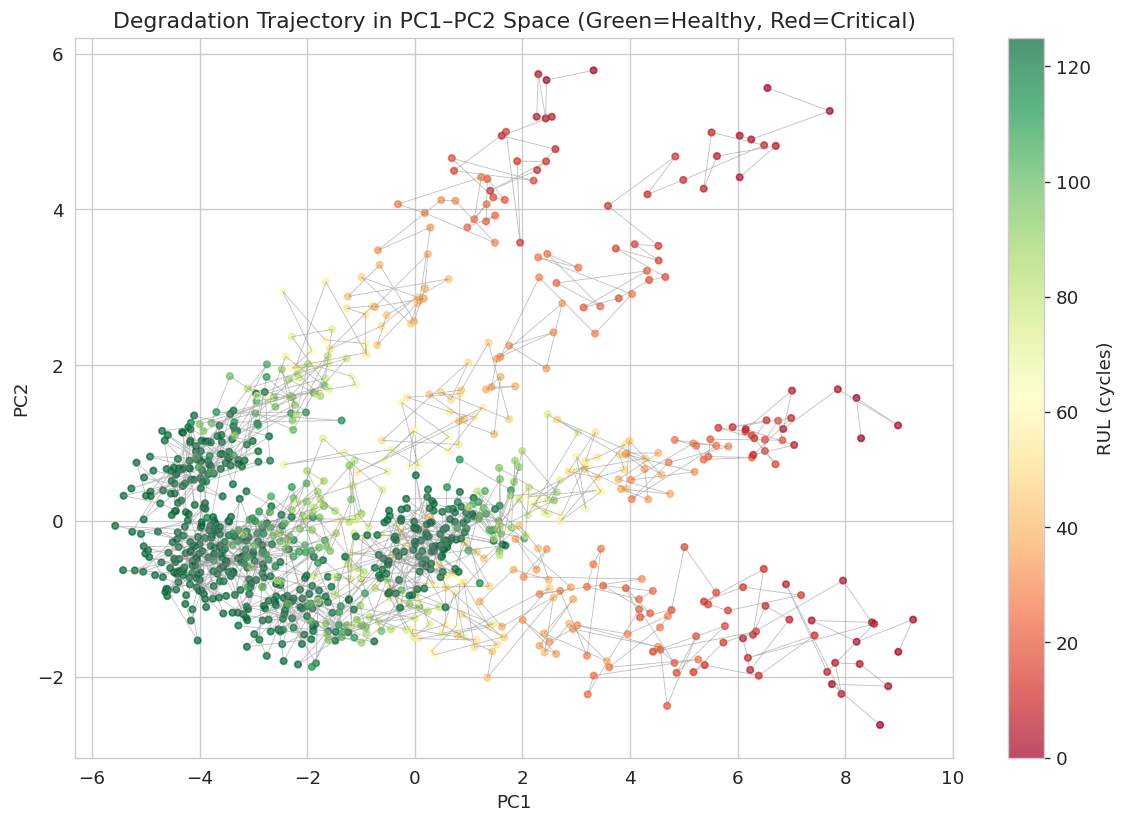

In [66]:
# Colour training points by RUL (shows degradation trajectory in PC space)
sample_units = [1, 5, 10, 15, 20]
fig, ax = plt.subplots(figsize=(10, 7))
cmap = plt.cm.RdYlGn

for uid in sample_units:
    grp = train_clean[train_clean['unit_id'] == uid].sort_values('cycle')
    raw = grp[selected_sensors].values
    pcs = pca.transform(raw)
    rul_vals = grp['RUL'].values
    sc = ax.scatter(pcs[:, 0], pcs[:, 1], c=rul_vals, cmap=cmap,
                    vmin=0, vmax=RUL_CAP, s=15, alpha=0.7)
    ax.plot(pcs[:, 0], pcs[:, 1], color='gray', linewidth=0.5, alpha=0.5)

plt.colorbar(sc, ax=ax, label='RUL (cycles)')
ax.set(title='Degradation Trajectory in PC1–PC2 Space (Green=Healthy, Red=Critical)',
       xlabel='PC1', ylabel='PC2')
plt.tight_layout()
plt.savefig('pca_degradation_trajectory.png', bbox_inches='tight')
plt.show()

---
## 20. Final Results Summary

     FINAL MODEL PERFORMANCE SUMMARY
         Metric     Train    Test
           RMSE     30.24   30.11
            MAE     24.16   23.40
     NASA Score 427279.91 9993.96
N_STATES (best)         5       5
 PCA Components        10      10


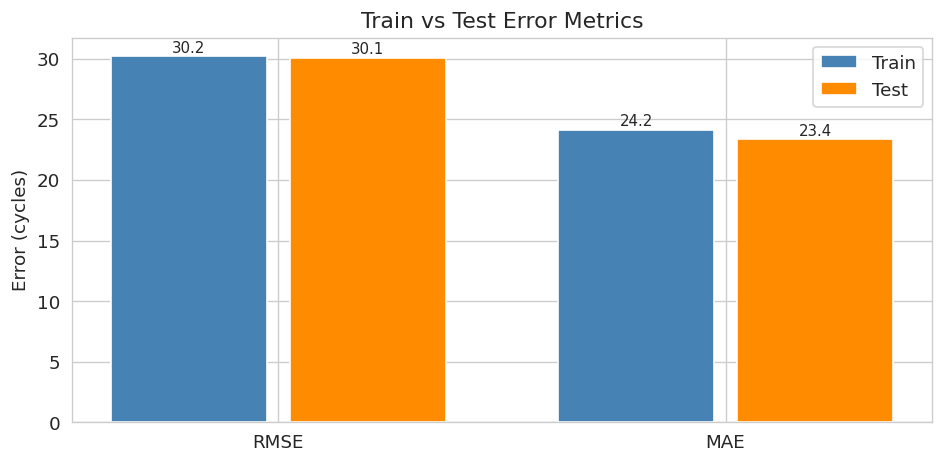


All plots saved. Notebook complete.


In [67]:
#  Metric summary table 
summary = pd.DataFrame({
    'Metric'      : ['RMSE', 'MAE', 'NASA Score', 'N_STATES (best)', 'PCA Components'],
    'Train'       : [f'{rmse_train:.2f}', f'{mae_train:.2f}', f'{train_nasa:.2f}',
                     str(N_STATES_BEST), str(n_components)],
    'Test'        : [f'{rmse_test:.2f}',  f'{mae_test:.2f}',  f'{nasa_test:.2f}',
                     str(N_STATES_BEST), str(n_components)],
})
print('=' * 50)
print('     FINAL MODEL PERFORMANCE SUMMARY')
print('=' * 50)
print(summary.to_string(index=False))
print('=' * 50)

# Bar chart of metrics
fig, ax = plt.subplots(figsize=(8, 4))
metrics = ['RMSE', 'MAE']
train_vals = [rmse_train, mae_train]
test_vals  = [rmse_test, mae_test]
x = np.arange(len(metrics))
ax.bar(x - 0.2, train_vals, 0.35, label='Train', color='steelblue')
ax.bar(x + 0.2, test_vals,  0.35, label='Test',  color='darkorange')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set(title='Train vs Test Error Metrics', ylabel='Error (cycles)')
ax.legend()
for i, (tv, tv2) in enumerate(zip(train_vals, test_vals)):
    ax.text(i-0.2, tv+0.3, f'{tv:.1f}', ha='center', fontsize=9)
    ax.text(i+0.2, tv2+0.3, f'{tv2:.1f}', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('final_metrics_summary.png', bbox_inches='tight')
plt.show()

print('\nAll plots saved. Notebook complete.')

---
## 21. Comparison with Baseline (Mean RUL Predictor)

In [68]:
# Naive baseline: always predict the mean RUL from training
mean_rul_baseline = np.full_like(true_final_rul, fill_value=all_true.mean(), dtype=float)
rmse_baseline = np.sqrt(mean_squared_error(true_final_rul, mean_rul_baseline))
mae_baseline  = mean_absolute_error(true_final_rul, mean_rul_baseline)

print('Comparison: PCA-HMM vs Baseline (Mean Predictor)')
print(f'  Baseline RMSE : {rmse_baseline:.2f}  |  HMM RMSE : {rmse_test:.2f}  |  Improvement: {100*(rmse_baseline-rmse_test)/rmse_baseline:.1f}%')
print(f'  Baseline MAE  : {mae_baseline:.2f}  |  HMM MAE  : {mae_test:.2f}  |  Improvement: {100*(mae_baseline-mae_test)/mae_baseline:.1f}%')

Comparison: PCA-HMM vs Baseline (Mean Predictor)
  Baseline RMSE : 42.61  |  HMM RMSE : 30.11  |  Improvement: 29.3%
  Baseline MAE  : 35.90  |  HMM MAE  : 23.40  |  Improvement: 34.8%


---
## Conclusion

This notebook demonstrated a complete **Explainable Prognostic Health Management (PHM)** pipeline:

| Stage | Technique |
|---|---|
| Data Cleaning | IQR outlier removal, zero-variance sensor pruning |
| Feature Engineering | Z-score normalisation, sliding window time series |
| Dimensionality Reduction | PCA (95% variance threshold) |
| Modelling | Gaussian HMM with Adaptive Left-Right Topology |
| Training | Expectation-Maximisation (EM), 200 iterations |
| Novelty | Physical monotonicity constraint embedded in transition matrix |
| Output | Health state probabilities + weighted RUL estimate + confidence |

**Key advantages of the approach:**
- **Explainability** — outputs named health states with posterior probabilities
- **Physical Consistency** — Left-Right topology enforces monotonic degradation
- **Confidence Quantification** — every prediction has an uncertainty estimate via state posteriors